# Lab: XAI and Uncertainty for Time-Series Forecasting (Panama Load)

You are data scientists at a grid operator in Panama. Your task is short-term load forecasting, interpreting model behaviour (XAI), and estimating predictive uncertainty so operators can make safer operational decisions. This notebook walks you through EDA, feature engineering, training a model, SHAP explanations, temporal attribution with occlusion, bootstrap-based variability, and conformal prediction intervals.

Follow the TODO markers in code cells. The dataset is expected at `data/panama_load.csv` and should contain at least a timestamp column and a load column. Optional covariates (temperature, humidity, etc.) are welcome.

In [1]:
# Section 0 - Setup
# Imports, plotting style, and random seed
import os
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import shap

# Plot style and seed
sns.set_style('whitegrid')
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option('display.precision', 3)

**Nota sobre la plantilla.** Al ejecutar el notebook aparecieron algunos problemas que he corregido. Cada cambio se explica en su sección:

1. **Datos:** el fichero es `data/panama_load.csv` (relativo a la raíz del repositorio, `../data/` desde la carpeta `notebook/`) y la demanda está en la columna `nat_demand`.
2. **`make_supervised` desalineaba features y objetivo:** en la fila *t* se usaba `lag_1 = y(t-1)` pero el objetivo era `y(t+1)`. En la práctica era una previsión a 2 pasos que no usaba la última observación, y el "naive" no era el valor anterior. Ahora cada fila se indexa por el instante que se quiere predecir.
3. **`mean_squared_error(..., squared=False)`** ya no existe en scikit-learn 1.7. Se usa `root_mean_squared_error`.
4. **Occlusion:** el `feature_builder` devolvía la fila de *t-2* en vez de la de *t* (por el `dropna` del objetivo), y la figura salía vacía porque se mezclaba el eje de fechas de pandas con el de matplotlib.
5. **SHAP:** la *waterfall* necesita un objeto `Explanation`, no un array de `shap_values`.

## Section 1 — Load data and basic EDA

Goal: understand the time series, inspect seasonality, and spot anomalies. Follow instructions and fill TODOs.

In [2]:
# 1) Load data into a DataFrame
# The notebook lives in notebook/, but it can also be run from the repository root
candidates = ['../data/panama_load.csv', 'data/panama_load.csv']
path = next((p for p in candidates if os.path.exists(p)), candidates[0])
if not os.path.exists(path):
    print(f'WARNING: {path} not found. Please place the dataset at this path.')
df = pd.read_csv(path)
# Quick peek
print('shape:', getattr(df, 'shape', None))
datetime_col = 'datetime'
load_col = 'nat_demand'  # national electricity demand (MW)
# Attempt to parse a datetime column robustly
if datetime_col not in df.columns:
    # try to guess a datetime-like column
    for c in df.columns:
        if 'date' in c.lower() or 'time' in c.lower():
            datetime_col = c
            break
print('Using datetime column:', datetime_col)
# Parse datetimes
try:
    df[datetime_col] = pd.to_datetime(df[datetime_col])
except Exception as e:
    print('Error parsing datetimes:', e)
# Set index and sort
df = df.set_index(datetime_col).sort_index()
# Ensure load column exists
if load_col not in df.columns:
    # try common alternatives
    for alt in ['demand', 'load', 'Load', 'LOAD', 'value']:
        if alt in df.columns:
            load_col = alt
            break
print('Using load column:', load_col)
# Keep a clean dataframe with at least datetime index and load
data = df[[load_col]].copy()
data.columns = ['load']
data = data.sort_index()
# Covariates: weather at Tocumen (toc, Panama City), Santiago (san) and David (dav) + holiday/school calendar
exog_all = df.drop(columns=[load_col])
print('Covariates:', list(exog_all.columns))
data.head()

shape: (48048, 17)
Using datetime column: datetime
Using load column: nat_demand
Covariates: ['T2M_toc', 'QV2M_toc', 'TQL_toc', 'W2M_toc', 'T2M_san', 'QV2M_san', 'TQL_san', 'W2M_san', 'T2M_dav', 'QV2M_dav', 'TQL_dav', 'W2M_dav', 'Holiday_ID', 'holiday', 'school']


,load
datetime,
2015-01-03 01:00:00,970.345
2015-01-03 02:00:00,912.176
2015-01-03 03:00:00,900.269
2015-01-03 04:00:00,889.954
2015-01-03 05:00:00,893.687


In [3]:
# Data quality: regular hourly grid, duplicates, missing values and extreme values
full_range = pd.date_range(data.index.min(), data.index.max(), freq='h')
print('Period:', data.index.min(), '->', data.index.max(), f'({len(data)} hours)')
print('Missing hours:', len(full_range.difference(data.index)),
      '| duplicated timestamps:', data.index.duplicated().sum(),
      '| NaNs:', int(df.isna().sum().sum()))
print(data['load'].describe().round(1).to_string())
# Largest hour-to-hour drops: candidates for outages or metering problems
print('\nLargest hourly drops (MW):')
print(data['load'].diff().nsmallest(8).round(1).to_string())

Period: 2015-01-03 01:00:00 -> 2020-06-27 00:00:00 (48048 hours)
Missing hours: 0 | duplicated timestamps: 0 | NaNs: 0
count    48048.0
mean      1182.9
std        192.1
min         85.2
25%       1020.1
50%       1168.4
75%       1327.6
max       1754.9

Largest hourly drops (MW):
datetime
2017-06-27 12:00:00   -1090.7
2017-07-01 14:00:00    -782.2
2019-01-20 12:00:00    -619.4
2017-03-21 19:00:00    -549.3
2015-01-24 17:00:00    -458.1
2019-01-20 11:00:00    -369.6
2017-03-17 21:00:00    -349.2
2017-03-17 20:00:00    -293.6


**Calidad de los datos.** La serie es horaria, del 03/01/2015 al 27/06/2020 (48 048 horas), sin huecos, sin timestamps duplicados y sin valores faltantes. Por eso no hace falta imputar nada. Lo que sí hay son caídas bruscas de demanda en una sola hora: 27/06/2017 (−1091 MW), 01/07/2017 (−782 MW), 20/01/2019 (la demanda baja a 85 MW), 21/03/2017, 24/01/2015... Por su forma (caída instantánea y recuperación en pocas horas) parecen apagones o fallos de medida. Las dejo en los datos porque son eventos reales del sistema, pero hay que tenerlas en cuenta: inflan algunos residuos y el modelo no puede anticiparlas.

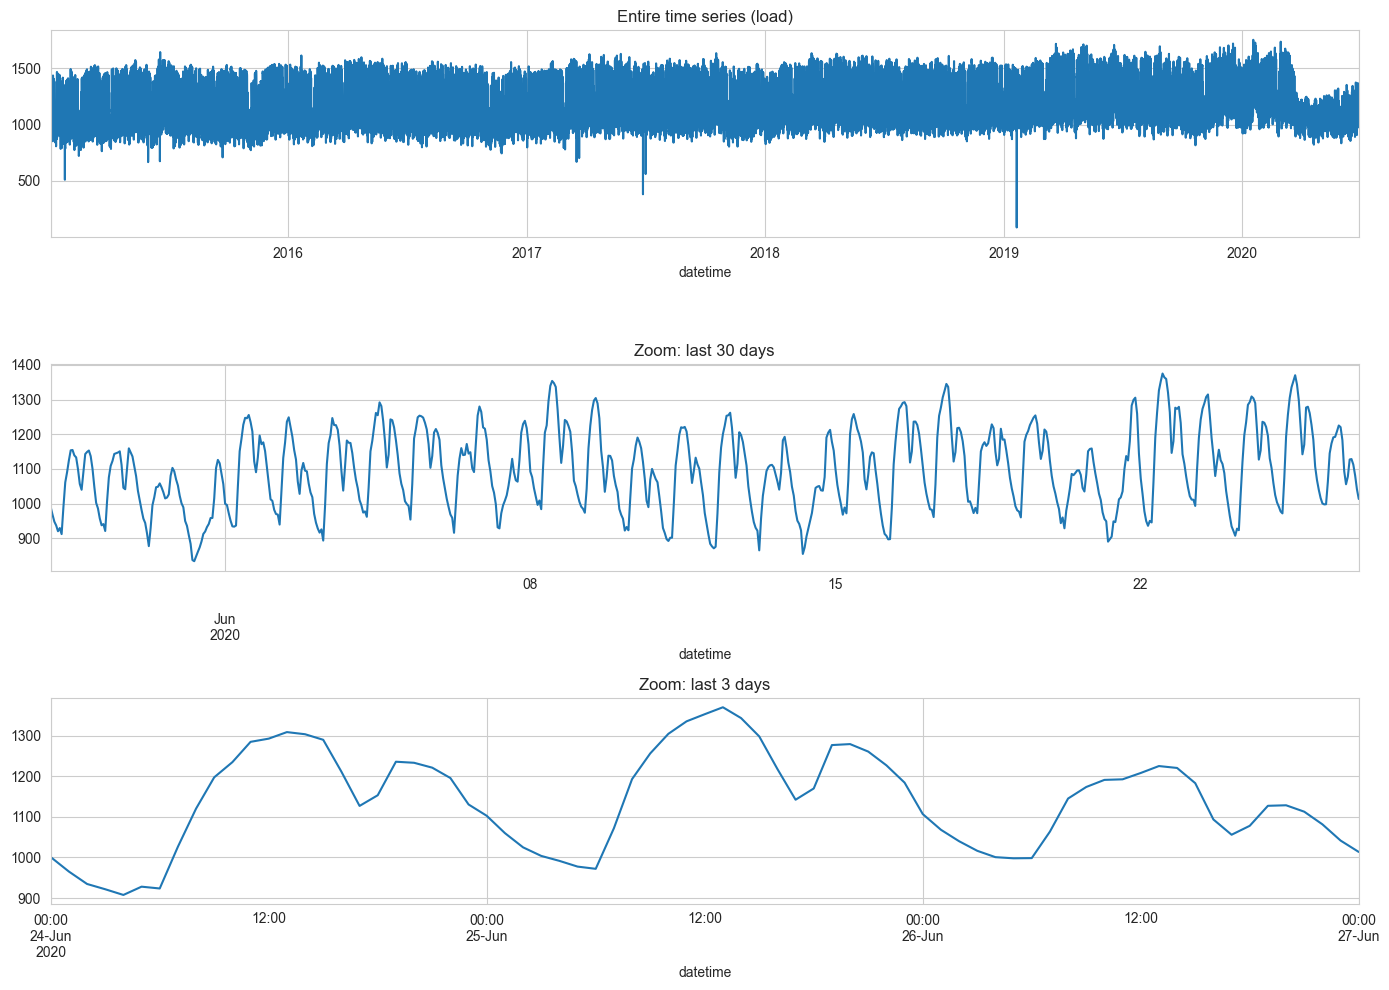

In [4]:
# 2) Basic plots: entire series, one month, a couple of days
fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
# Entire series
data['load'].plot(ax=ax[0], title='Entire time series (load)')
# Zoom into one month (choose the last available month)
try:
    last = data.index.max()
    month_start = (last - pd.Timedelta(days=30)).ceil('D')
    data.loc[month_start:last, 'load'].plot(ax=ax[1], title='Zoom: last 30 days')
except Exception:
    ax[1].text(0.5, 0.5, 'Not enough data for a 30-day zoom', ha='center')
# Zoom into a couple of days
try:
    days_start = (last - pd.Timedelta(days=3)).ceil('D')
    data.loc[days_start:last, 'load'].plot(ax=ax[2], title='Zoom: last 3 days')
except Exception:
    ax[2].text(0.5, 0.5, 'Not enough data for a 3-day zoom', ha='center')
plt.tight_layout()
plt.show()

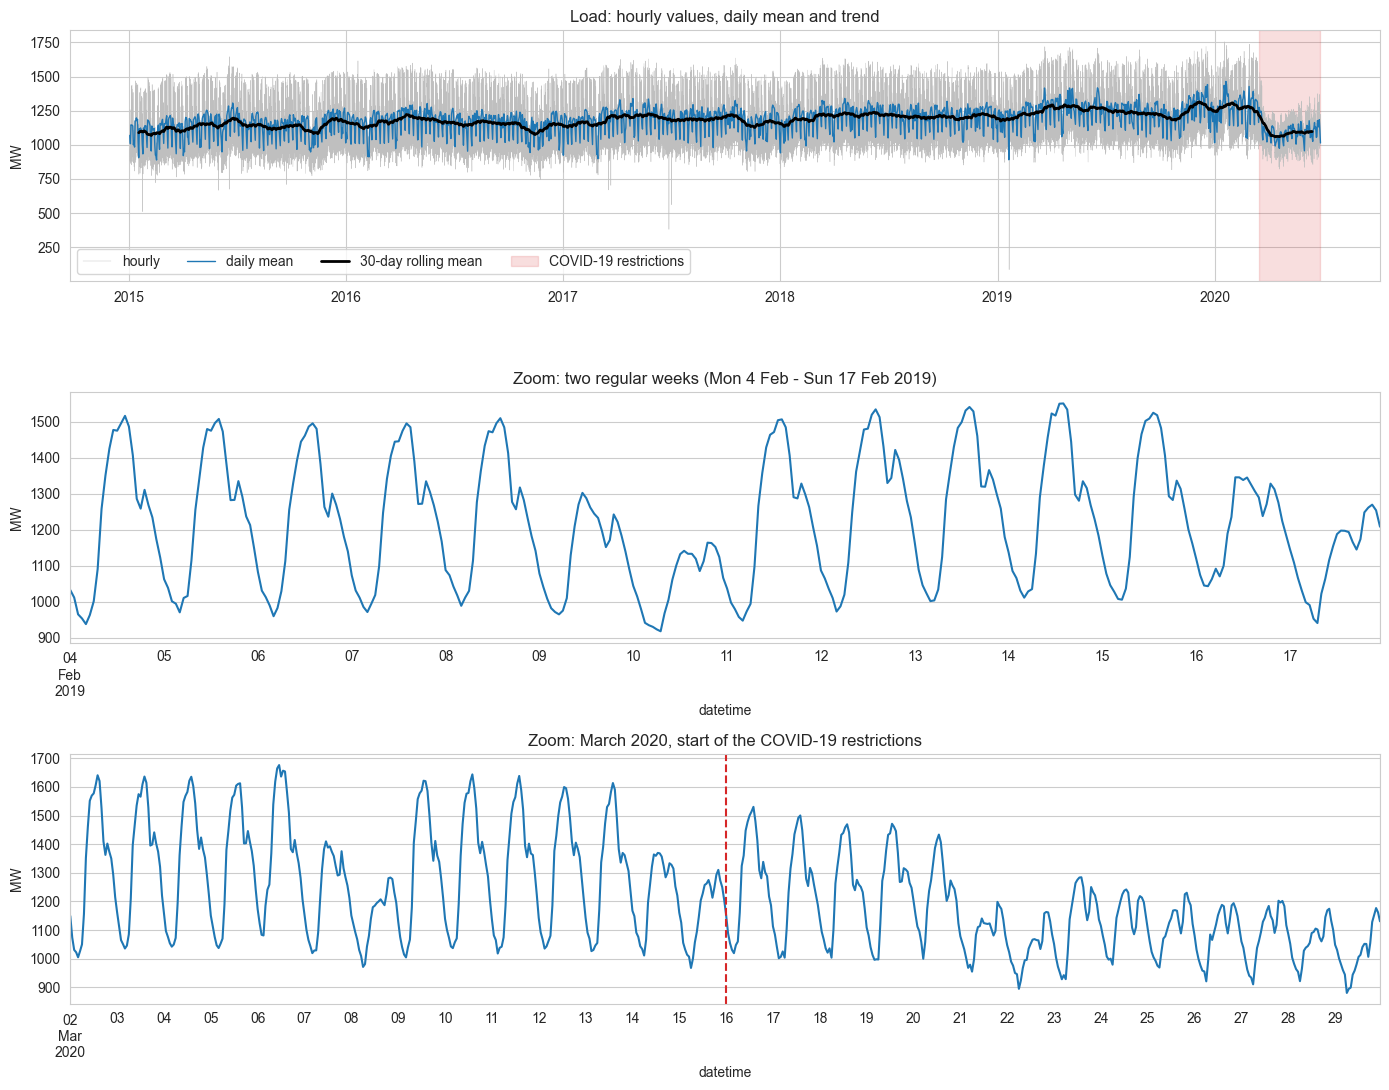

In [5]:
# Other zooms: hourly values + daily mean of the whole period, two regular weeks and March 2020 (COVID-19)
COVID_START = pd.Timestamp('2020-03-16')  # first Monday with restrictions in force
daily = data['load'].resample('D').mean()
fig, ax = plt.subplots(3, 1, figsize=(14, 11))
ax[0].plot(data.index, data['load'], color='0.75', lw=0.3, label='hourly')
ax[0].plot(daily.index, daily.values, color='C0', lw=1, label='daily mean')
ax[0].plot(daily.index, daily.rolling(30, center=True).mean(), color='k', lw=2, label='30-day rolling mean')
ax[0].axvspan(COVID_START, data.index.max(), color='C3', alpha=0.15, label='COVID-19 restrictions')
ax[0].set_title('Load: hourly values, daily mean and trend')
ax[0].set_ylabel('MW')
ax[0].legend(loc='lower left', ncol=4)
data.loc['2019-02-04':'2019-02-17', 'load'].plot(ax=ax[1], title='Zoom: two regular weeks (Mon 4 Feb - Sun 17 Feb 2019)')
data.loc['2020-03-02':'2020-03-29', 'load'].plot(ax=ax[2], title='Zoom: March 2020, start of the COVID-19 restrictions')
ax[2].axvline(COVID_START, color='C3', ls='--')
for a in ax[1:]:
    a.set_ylabel('MW')
plt.tight_layout()
plt.show()

**Comentarios sobre la serie.**

- **Tendencia:** la demanda media crece de forma sostenida, de unos 1090 MW a comienzos de 2015 a casi 1300 MW a finales de 2019 (en torno a un 3 % anual). Esto importa para los árboles, que no extrapolan: el periodo de test tiene niveles más altos que el de entrenamiento.
- **Estacionalidad anual:** los meses más altos suelen ser marzo-mayo (los más calurosos, al final de la estación seca) y diciembre-enero; noviembre es más bajo por las fiestas patrias (3, 4, 5, 10 y 28 de noviembre).
- **Estacionalidad diaria y semanal:** en el zoom de febrero de 2019 se ve el ciclo diario (mínimo de madrugada, subida rápida por la mañana y meseta al mediodía) y que sábado y domingo son claramente más bajos.
- **COVID-19:** a mediados de marzo de 2020 la demanda cae de forma abrupta. Los días laborables pasan de picos de unos 1600 MW a unos 1150-1250 MW, y el patrón semanal casi desaparece. Abril de 2020 queda un 17 % por debajo de abril de 2019. Es un cambio estructural que cae dentro del conjunto de test.
- **Valores atípicos:** los picos hacia abajo de 2015, 2017 y enero de 2019 son las caídas detectadas en la celda anterior.

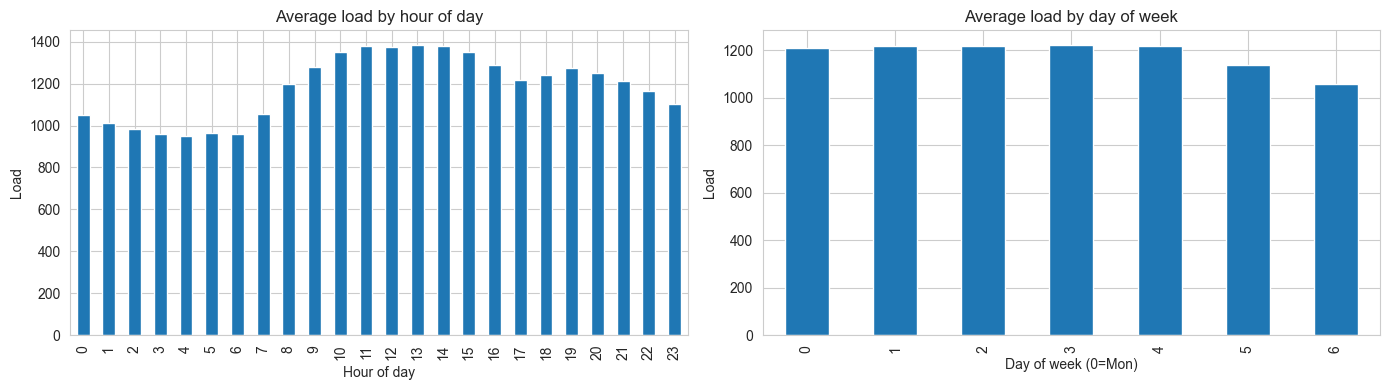

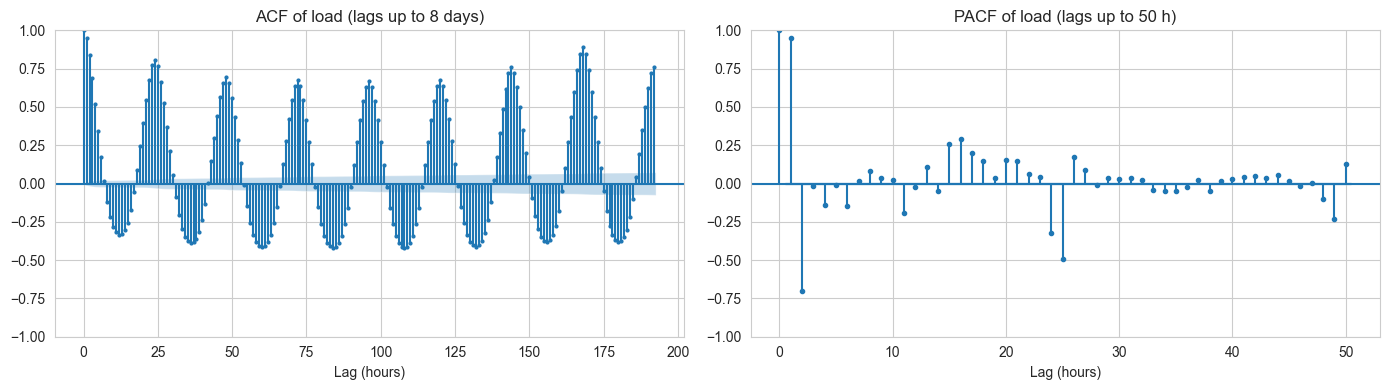

In [6]:
# 3) Average load by hour-of-day and day-of-week
df_feats = data.copy()
df_feats['hour'] = df_feats.index.hour
df_feats['dow'] = df_feats.index.dayofweek
hourly = df_feats.groupby('hour')['load'].mean()
dow = df_feats.groupby('dow')['load'].mean()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
hourly.plot(kind='bar', ax=ax1, title='Average load by hour of day')
ax1.set_xlabel('Hour of day')
ax1.set_ylabel('Load')
dow.plot(kind='bar', ax=ax2, title='Average load by day of week')
ax2.set_xlabel('Day of week (0=Mon)')
ax2.set_ylabel('Load')
plt.tight_layout()
plt.show()
# ACF (8 days of lags) and PACF (first 50 lags)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(data['load'].dropna(), lags=24 * 8, ax=ax[0], markersize=2, title='ACF of load (lags up to 8 days)')
plot_pacf(data['load'].dropna(), lags=50, ax=ax[1], method='ywm', markersize=3, title='PACF of load (lags up to 50 h)')
for a in ax:
    a.set_xlabel('Lag (hours)')
plt.tight_layout()
plt.show()

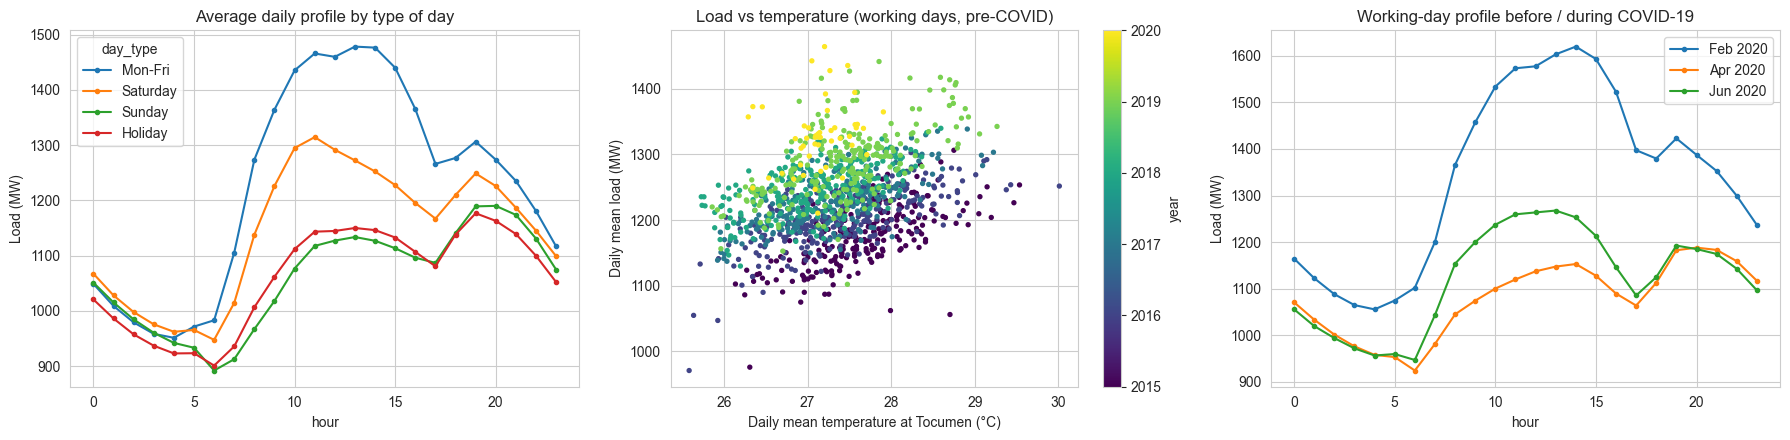

Correlation daily temperature - daily load (working days, pre-COVID): 0.322
  within 2016: 0.693
  within 2018: 0.589


In [7]:
# Daily profile by type of day, relation with temperature and change of the profile with COVID-19
prof = df_feats.join(exog_all[['holiday', 'T2M_toc']])
prof['day_type'] = np.select([prof['holiday'] == 1, prof['dow'] == 6, prof['dow'] == 5],
                             ['Holiday', 'Sunday', 'Saturday'], default='Mon-Fri')
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
prof.groupby(['hour', 'day_type'])['load'].mean().unstack()[['Mon-Fri', 'Saturday', 'Sunday', 'Holiday']].plot(ax=ax[0], marker='.')
ax[0].set_title('Average daily profile by type of day')
ax[0].set_ylabel('Load (MW)')
# Daily mean temperature in Panama City vs daily mean load (working days before COVID-19), coloured by year
dd = prof[prof['day_type'] == 'Mon-Fri'].resample('D')[['load', 'T2M_toc']].mean().dropna()
dd = dd[dd.index < COVID_START]
sc = ax[1].scatter(dd['T2M_toc'], dd['load'], c=dd.index.year, cmap='viridis', s=8)
plt.colorbar(sc, ax=ax[1], label='year')
ax[1].set_xlabel('Daily mean temperature at Tocumen (°C)')
ax[1].set_ylabel('Daily mean load (MW)')
ax[1].set_title('Load vs temperature (working days, pre-COVID)')
# Average working-day profile before and during the restrictions
wd = prof[prof['day_type'] == 'Mon-Fri']
for lab, (a, b) in {'Feb 2020': ('2020-02-01', '2020-02-29'), 'Apr 2020': ('2020-04-01', '2020-04-30'),
                    'Jun 2020': ('2020-06-01', '2020-06-30')}.items():
    wd.loc[a:b].groupby('hour')['load'].mean().plot(ax=ax[2], marker='.', label=lab)
ax[2].set_title('Working-day profile before / during COVID-19')
ax[2].set_ylabel('Load (MW)')
ax[2].legend()
plt.tight_layout()
plt.show()
print('Correlation daily temperature - daily load (working days, pre-COVID):', round(dd['T2M_toc'].corr(dd['load']), 3))
for yr in [2016, 2018]:
    d = dd[dd.index.year == yr]
    print(f'  within {yr}:', round(d['T2M_toc'].corr(d['load']), 3))

**Comentarios sobre la estacionalidad.**

- **Diaria:** mínimo entre las 3 y las 6 h (~950 MW), rampa muy pronunciada de 6 a 10 h, meseta entre las 11 y las 15 h (máximo ~1380 MW de media, ~1470 MW en laborables) y un segundo pico hacia las 19-20 h. El pico de mediodía es comercial y de climatización; el de la tarde-noche es más residencial (iluminación), por eso se mantiene incluso en domingos y festivos.
- **Semanal:** de lunes a viernes el nivel es casi idéntico (~1210-1220 MW), el sábado baja a ~1140 y el domingo a ~1060 MW. Los festivos tienen un perfil prácticamente igual al del domingo.
- **ACF/PACF:** la ACF tiene picos cada 24 h y el de 168 h (~0.89) es más alto que el de 24 h (~0.80), lo que confirma la estacionalidad semanal. La PACF es muy grande en el retardo 1 (~0.95), negativa en el 2 y vuelve a ser significativa alrededor de 24-26 y 48-49 h. Esto justifica usar `lag_1`, `lag_2`, `lag_3`, `lag_24`, `lag_48` y `lag_168`.
- **Temperatura:** la correlación diaria temperatura-demanda es solo 0.32 con todos los años juntos, pero sube a 0.59-0.69 dentro de un mismo año. La tendencia actúa como factor de confusión (cada año está desplazado hacia arriba). Más calor implica más demanda (aire acondicionado), como era de esperar en un clima tropical.
- **COVID-19:** en abril de 2020 un día laborable se parece a un domingo: el pico de mediodía cae de ~1620 a ~1150 MW, mientras que la madrugada y el pico de la tarde casi no cambian. En junio hay una recuperación parcial.

## Section 2 — Turn time series into supervised learning data

We convert the time series into a tabular supervised problem: predict 1-step-ahead load from lag features, rolling statistics and calendar features.
Fill TODOs in the helper function below.

In [8]:
LAGS = [1, 2, 3, 24, 48, 168]
WEATHER_COLS = ['T2M_toc', 'T2M_san', 'T2M_dav', 'QV2M_toc', 'TQL_toc', 'W2M_toc']
CALENDAR_COLS = ['holiday', 'school']


def make_supervised(df, target_col='load', horizon=1, lags=None, exog=None, dropna=True):
    """Create supervised features for a `horizon`-step-ahead forecast.

    Each row is indexed by the time t to be predicted (target = load at t) and only uses the load
    observed up to t - horizon. Holiday/school flags are known in advance, so they are taken at t.
    Weather covariates are shifted `horizon` hours (measured values only, no weather forecast).
    """
    if lags is None:
        lags = [1, 24, 48, 168]  # t-1, t-24 (daily), t-48, t-168 (weekly)
    lags = [lag for lag in lags if lag >= horizon]
    s = df[target_col]
    X = pd.DataFrame(index=df.index)
    # Lag features
    for lag in lags:
        X[f'lag_{lag}'] = s.shift(lag)
    # Rolling features: 24-hour and 7-day statistics of the history available when the forecast is made
    past = s.shift(horizon)
    X['rmean_24'] = past.rolling(window=24, min_periods=24).mean()
    X['rstd_24'] = past.rolling(window=24, min_periods=24).std()
    X['rmean_168'] = past.rolling(window=168, min_periods=168).mean()
    # Calendar features of the target time
    X['hour'] = df.index.hour
    X['dow'] = df.index.dayofweek
    X['is_weekend'] = (X['dow'] >= 5).astype(int)
    X['month'] = df.index.month
    # Exogenous covariates
    if exog is not None:
        ex = exog.reindex(df.index)
        for c in ex.columns:
            X[c] = ex[c] if c in CALENDAR_COLS else ex[c].shift(horizon)
    # Target: load at t
    y = s.copy()
    if dropna:
        # drop warm-up rows (incomplete lags / rolling windows) and missing targets
        keep = X.notna().all(axis=1) & y.notna()
        X, y = X.loc[keep], y.loc[keep]
    return X, y


# Build supervised data: template lags + lags 2-3, holiday/school calendar and weather
exog_model = exog_all[WEATHER_COLS + CALENDAR_COLS]
X, y = make_supervised(data, target_col='load', horizon=1, lags=LAGS, exog=exog_model)
print('X shape:', X.shape, 'y shape:', y.shape)
# lag_1 must be the load observed one hour before the target
assert (X['lag_1'] == data['load'].shift(1).loc[X.index]).all()
# show a few rows
X.head()

X shape: (47880, 21) y shape: (47880,)


,lag_1,lag_2,lag_3,lag_24,lag_48,lag_168,rmean_24,rstd_24,rmean_168,hour,...,is_weekend,month,T2M_toc,T2M_san,T2M_dav,QV2M_toc,TQL_toc,W2M_toc,holiday,school
datetime,,,,,,,,,,,,,,,,,,,,,
2015-01-10 01:00:00,949.503,989.851,1033.864,943.608,962.407,970.345,999.014,78.863,1092.048,1,...,1,1,25.053,23.670,22.311,0.017,0.022,20.918,0,0
2015-01-10 02:00:00,906.958,949.503,989.851,917.064,928.104,912.176,997.487,80.324,1091.670,2,...,1,1,24.976,23.555,22.289,0.017,0.025,21.335,0,0
2015-01-10 03:00:00,863.514,906.958,949.503,895.909,918.000,900.269,995.255,83.342,1091.381,3,...,1,1,24.906,23.430,22.297,0.017,0.034,22.177,0,0
2015-01-10 04:00:00,848.445,863.514,906.958,885.272,910.954,889.954,993.278,86.312,1091.072,4,...,1,1,24.880,23.309,22.325,0.018,0.045,22.742,0,0
2015-01-10 05:00:00,839.882,848.445,863.514,884.811,928.724,893.687,991.387,89.230,1090.774,5,...,1,1,24.908,23.306,22.369,0.018,0.048,22.630,0,0


**Cambios en `make_supervised`.**

- **Alineación:** la fila con índice *t* contiene el objetivo `y(t)` y solo información disponible en *t-1* (horizonte 1). En la plantilla, `y = shift(-1)` con `lag_1 = shift(1)` dejaba un hueco de dos horas entre la última observación usada y el objetivo (ver la tabla de la celda siguiente). Además, las variables de calendario eran las de *t* y no las de *t+1*.
- **Arranque (warm-up):** las medias móviles se calculaban con `min_periods=1`, así que las primeras filas tenían estadísticos con muy pocos datos y `lag_168` era NaN. Ahora se exige la ventana completa y se eliminan las 168 primeras horas.
- **Nuevas variables:** `lag_2` y `lag_3` (pendiente reciente, útil en las rampas), `holiday` y `school` (se conocen de antemano, así que se toman en *t*), y la meteorología de Tocumen, Santiago y David retrasada una hora. Con ese retraso solo se usan valores ya medidos y no hay fuga de información. En producción se podría usar una previsión meteorológica.
- El `assert` comprueba que `lag_1` es exactamente la demanda de la hora anterior al objetivo.

In [9]:
# Template vs corrected alignment on a toy series whose value is the hour number
toy = pd.DataFrame({'load': np.arange(8.0)}, index=pd.date_range('2020-01-01', periods=8, freq='h'))
X_toy, y_toy = make_supervised(toy, lags=[1], dropna=False)
pd.DataFrame({'lag_1': X_toy['lag_1'],
              'target (template: shift(-1))': toy['load'].shift(-1),
              'target (corrected)': y_toy}).iloc[1:6]

,lag_1,target (template: shift(-1)),target (corrected)
2020-01-01 01:00:00,0.0,2.0,1.0
2020-01-01 02:00:00,1.0,3.0,2.0
2020-01-01 03:00:00,2.0,4.0,3.0
2020-01-01 04:00:00,3.0,5.0,4.0
2020-01-01 05:00:00,4.0,6.0,5.0


## Section 3 — Time-based train / calibration / test split

Random splits leak future information in time series. We'll split chronologically: TRAIN (first 60%), CALIBRATION (next 20%), TEST (last 20%). The calibration set will be used for conformal prediction intervals.


In [10]:
# Chronological split
n = len(X)
i_train = int(n * 0.6)
i_cal = int(n * 0.8)
X_train = X.iloc[:i_train]
y_train = y.iloc[:i_train]
X_cal = X.iloc[i_train:i_cal]
y_cal = y.iloc[i_train:i_cal]
X_test = X.iloc[i_cal:]
y_test = y.iloc[i_cal:]
print('TRAIN range:', X_train.index.min(), 'to', X_train.index.max(), 'size', len(X_train))
print('CAL range:', X_cal.index.min(), 'to', X_cal.index.max(), 'size', len(X_cal))
print('TEST range:', X_test.index.min(), 'to', X_test.index.max(), 'size', len(X_test))

TRAIN range: 2015-01-10 01:00:00 to 2018-04-21 00:00:00 size 28728
CAL range: 2018-04-21 01:00:00 to 2019-05-25 00:00:00 size 9576
TEST range: 2019-05-25 01:00:00 to 2020-06-27 00:00:00 size 9576


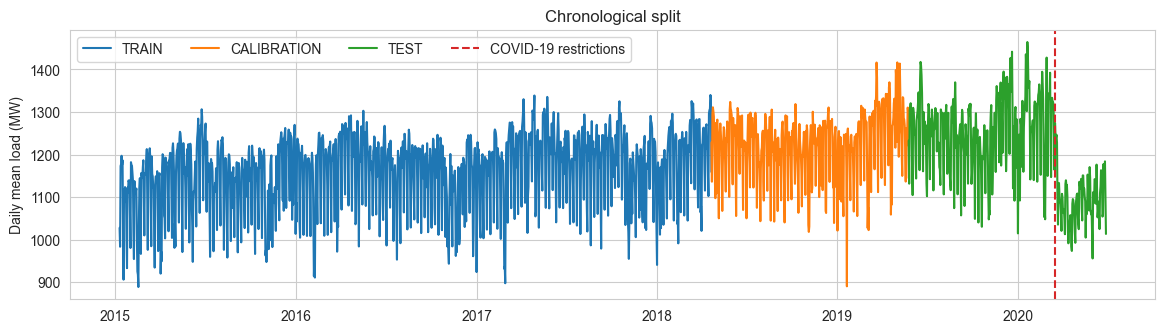

Share of TEST hours after 2020-03-16: 25.8%
Mean load  TRAIN 1161 | CAL 1222 | TEST 1212 MW
TEST hours above the TRAIN maximum (1645 MW): 67


In [11]:
# Visualise the three blocks
fig, ax = plt.subplots(figsize=(14, 3.5))
for (lab, yy), col in zip({'TRAIN': y_train, 'CALIBRATION': y_cal, 'TEST': y_test}.items(), ['C0', 'C1', 'C2']):
    ax.plot(yy.resample('D').mean(), color=col, label=lab)
ax.axvline(COVID_START, color='C3', ls='--', label='COVID-19 restrictions')
ax.set_ylabel('Daily mean load (MW)')
ax.set_title('Chronological split')
ax.legend(ncol=4)
plt.show()
covid = y_test.index >= COVID_START
print(f'Share of TEST hours after {COVID_START.date()}: {covid.mean():.1%}')
print(f'Mean load  TRAIN {y_train.mean():.0f} | CAL {y_cal.mean():.0f} | TEST {y_test.mean():.0f} MW')
print(f'TEST hours above the TRAIN maximum ({y_train.max():.0f} MW): {(y_test > y_train.max()).sum()}')

**Comentarios sobre la partición.** TRAIN cubre enero de 2015 a abril de 2018, CAL de abril de 2018 a mayo de 2019 y TEST de mayo de 2019 a junio de 2020. Dos cosas condicionan el resto del análisis:

- El 25.8 % de TEST está dentro del periodo COVID, un régimen que el modelo nunca ha visto.
- La demanda media sube de 1161 MW (TRAIN) a 1222 MW (CAL) y 1212 MW (TEST), y hay 67 horas de TEST por encima del máximo de TRAIN (1645 MW), en los picos de diciembre de 2019 a febrero de 2020. Un modelo de árboles no puede predecir por encima de lo que vio en entrenamiento.

Por tanto, la hipótesis de intercambiabilidad entre CAL y TEST, que es la base de la garantía del conformal, no se cumple del todo. Lo veremos en la sección 8.

## Section 4 — Baseline model and ML model

We compare a naive baseline (previous value) to a trained tree-based regressor. Evaluate using MAE and RMSE.


In [12]:
# Naive baseline: with the corrected alignment lag_1 is the last observed load (persistence)
y_test_index = y_test.index
yhat_naive = X_test['lag_1']
# Seasonal naive baselines: same hour yesterday / same hour last week
yhat_snaive24 = X_test['lag_24']
yhat_snaive168 = X_test['lag_168']


# Evaluation
def evaluate(y_true, y_pred, label='model', verbose=True):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)  # mean_squared_error(..., squared=False) no longer exists in sklearn 1.7
    mape = 100 * np.mean(np.abs((y_true - y_pred) / y_true))
    if verbose:
        print(f'{label} MAE: {mae:.3f}, RMSE: {rmse:.3f}, MAPE: {mape:.2f}%')
    return {'model': label, 'MAE': mae, 'RMSE': rmse, 'MAPE_%': mape}


# Candidate feature sets / models, compared on an inner validation block (last 20% of TRAIN)
# so that the TEST set is not used to make modelling decisions
BASE_COLS = ['lag_1', 'lag_24', 'lag_48', 'lag_168', 'rmean_24', 'rstd_24', 'rmean_168', 'hour', 'dow', 'is_weekend', 'month']
feature_sets = {
    'template features': BASE_COLS,
    '+ lags 2,3': BASE_COLS + ['lag_2', 'lag_3'],
    '+ lags 2,3 + holiday/school': BASE_COLS + ['lag_2', 'lag_3'] + CALENDAR_COLS,
    '+ lags 2,3 + holiday/school + weather': list(X.columns),
}
candidate_models = {
    'RandomForest': lambda: RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1),
    'HistGB': lambda: HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=RANDOM_SEED),
}
k = int(len(X_train) * 0.8)
X_fit, y_fit, X_val, y_val = X_train.iloc[:k], y_train.iloc[:k], X_train.iloc[k:], y_train.iloc[k:]
print('Inner validation block:', X_val.index.min(), '->', X_val.index.max())
rows = [evaluate(y_val, X_val['lag_1'], label='Naive (t-1)', verbose=False)]
for fs_name, cols in feature_sets.items():
    for m_name, make_model in candidate_models.items():
        m = make_model().fit(X_fit[cols], y_fit)
        rows.append(evaluate(y_val, m.predict(X_val[cols]), label=f'{m_name} | {fs_name}', verbose=False))
val_results = pd.DataFrame(rows).set_index('model').sort_values('MAE')
val_results

Inner validation block: 2017-08-24 15:00:00 -> 2018-04-21 00:00:00


,MAE,RMSE,MAPE_%
model,,,
"HistGB | + lags 2,3 + holiday/school",12.758,17.016,1.079
"HistGB | + lags 2,3 + holiday/school + weather",12.869,17.110,1.085
"HistGB | + lags 2,3",13.003,17.551,1.105
HistGB | template features,13.125,17.771,1.115
"RandomForest | + lags 2,3 + holiday/school",13.310,18.649,1.125
"RandomForest | + lags 2,3 + holiday/school + weather",13.457,18.608,1.139
"RandomForest | + lags 2,3",13.486,19.033,1.143
RandomForest | template features,13.750,19.226,1.167
Naive (t-1),44.859,58.075,3.776


**Selección de modelo (validación interna, agosto de 2017 a abril de 2018).** No quería elegir el modelo mirando TEST, así que las comparaciones se hacen en el último 20 % de TRAIN:

- Todos los modelos mejoran muchísimo al naive (MAE ~13 frente a 45 MW).
- HistGradientBoosting es mejor que RandomForest con cualquier conjunto de variables, y además es mucho más rápido de entrenar y de explicar con TreeSHAP (árboles poco profundos). Es la implementación de scikit-learn del boosting por histogramas de LightGBM, así que cubre la sugerencia de probar XGBoost/LightGBM sin añadir dependencias al proyecto.
- `lag_2`/`lag_3` y los festivos aportan una mejora pequeña pero consistente. La meteorología no mejora a horizonte 1 h (12.87 frente a 12.76 MW), porque su efecto ya está contenido en `lag_1`.

Me quedo con **HistGB con todas las variables**. La diferencia con el mejor (0.1 MW, <1 %) es despreciable y así puedo comprobar con SHAP si el modelo usa la temperatura (pregunta de la sección 10). Si el objetivo fuera solo precisión, el modelo sin meteorología sería igual de válido y más simple.

In [13]:
# Final models trained on the whole TRAIN block
# RandomForest of the template (corrected alignment, template features)
model_rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
model_rf.fit(X_train[BASE_COLS], y_train)
yhat_rf = pd.Series(model_rf.predict(X_test[BASE_COLS]), index=X_test.index)
# Selected model: HistGradientBoosting with all the features. It is the `model` used in the rest of the notebook
model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=RANDOM_SEED)
model.fit(X_train, y_train)
# Predict on test
yhat = pd.Series(model.predict(X_test), index=X_test.index)
# Extension: learn the hourly increment y(t) - y(t-1) instead of the level
model_delta = clone(model).fit(X_train, y_train - X_train['lag_1'])
yhat_delta = pd.Series(model_delta.predict(X_test) + X_test['lag_1'], index=X_test.index)

preds_test = {
    'Naive (t-1)': yhat_naive,
    'Seasonal naive (t-24)': yhat_snaive24,
    'Seasonal naive (t-168)': yhat_snaive168,
    'RandomForest (template features)': yhat_rf,
    'HistGB (all features)': yhat,
    'HistGB, increment target': yhat_delta,
}
rows = []
for name, p in preds_test.items():
    r = evaluate(y_test, p, label=name, verbose=False)
    r['MAE pre-COVID'] = mean_absolute_error(y_test[~covid], p[~covid])
    r['MAE COVID'] = mean_absolute_error(y_test[covid], p[covid])
    r['bias (y - yhat)'] = (y_test - p).mean()
    rows.append(r)
test_results = pd.DataFrame(rows).set_index('model')
test_results

,MAE,RMSE,MAPE_%,MAE pre-COVID,MAE COVID,bias (y - yhat)
model,,,,,,
Naive (t-1),42.819,55.548,3.511,46.321,32.759,-0.014
Seasonal naive (t-24),74.574,112.233,6.027,81.631,54.303,-0.483
Seasonal naive (t-168),70.294,97.055,5.807,73.128,62.155,-2.070
RandomForest (template features),22.878,33.824,1.899,22.497,23.972,2.797
HistGB (all features),20.429,28.505,1.684,19.917,21.901,3.095
"HistGB, increment target",17.606,24.398,1.472,16.189,21.677,0.694


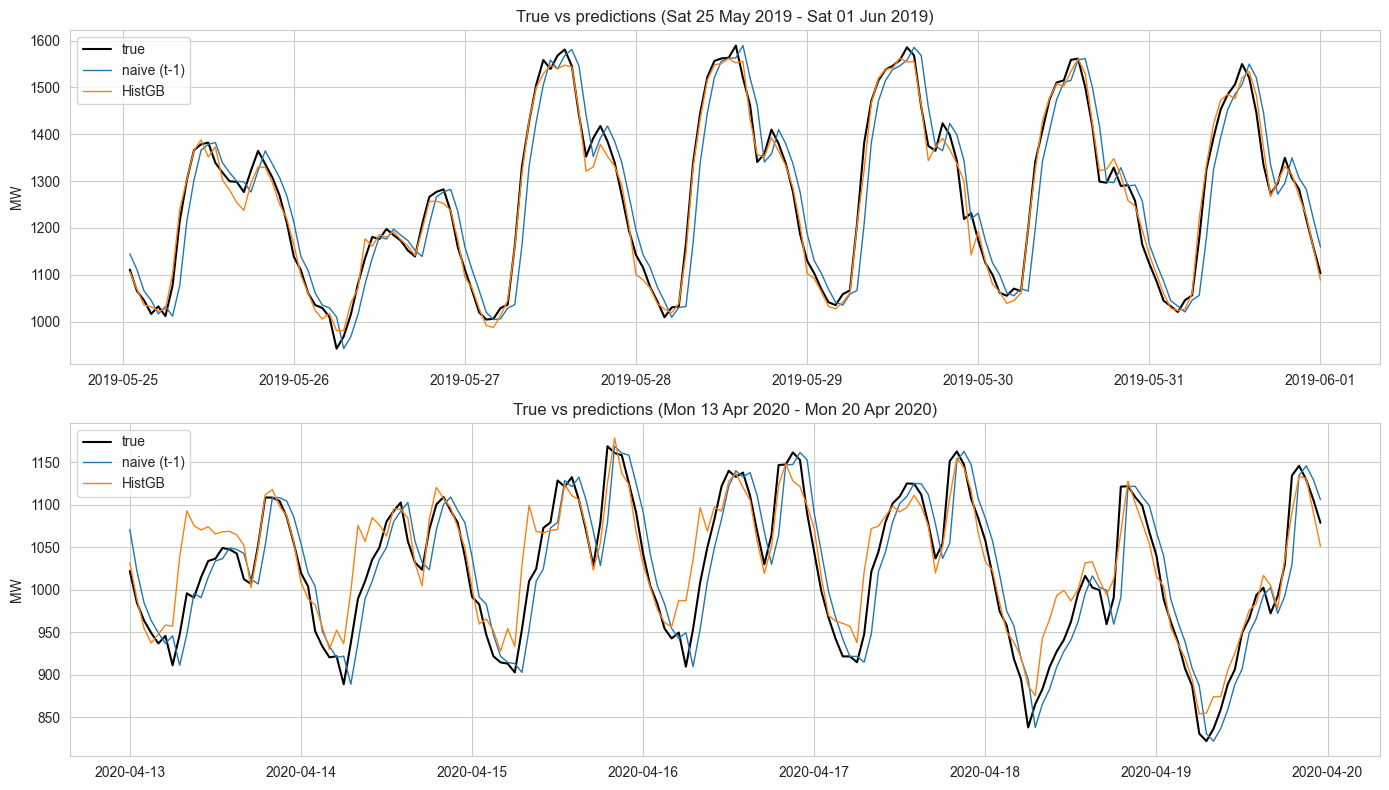

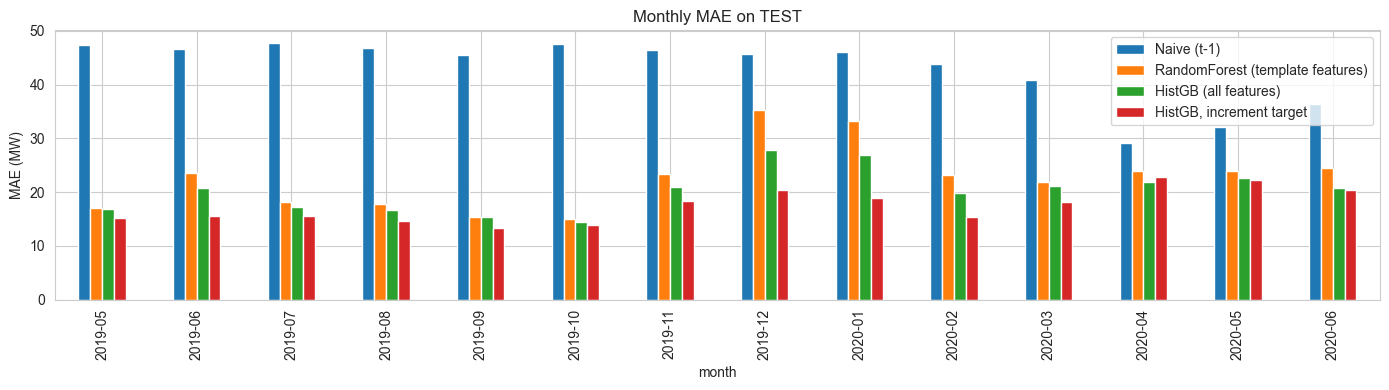

In [14]:
# Plot two TEST weeks: the first week of the test set and a week under COVID-19 restrictions
fig, ax = plt.subplots(2, 1, figsize=(14, 8))
for a, plot_start in zip(ax, [X_test.index[0], pd.Timestamp('2020-04-13')]):
    plot_end = plot_start + pd.Timedelta(days=7)
    idx = (y_test.index >= plot_start) & (y_test.index < plot_end)
    a.plot(y_test.index[idx], y_test[idx], label='true', color='k', lw=1.5)
    a.plot(y_test.index[idx], yhat_naive[idx], label='naive (t-1)', lw=1)
    a.plot(y_test.index[idx], yhat[idx], label='HistGB', lw=1)
    a.set_title(f'True vs predictions ({plot_start:%a %d %b %Y} - {plot_end:%a %d %b %Y})')
    a.set_ylabel('MW')
    a.legend()
plt.tight_layout()
plt.show()
# Monthly MAE on TEST
monthly_mae = pd.DataFrame({name: (y_test - preds_test[name]).abs().resample('ME').mean()
                            for name in ['Naive (t-1)', 'RandomForest (template features)', 'HistGB (all features)', 'HistGB, increment target']})
monthly_mae.index = monthly_mae.index.strftime('%Y-%m')
monthly_mae.plot(kind='bar', figsize=(14, 4), title='Monthly MAE on TEST', xlabel='month', ylabel='MAE (MW)')
plt.tight_layout()
plt.show()

**Resultados en TEST.**

- **Baselines:** con la alineación corregida, el naive (*t-1*) tiene un MAE de 42.8 MW (3.5 %). Los naive estacionales (*t-24*, *t-168*) son mucho peores a 1 h vista.
- **Modelos:** el RandomForest de la plantilla baja a 22.9 MW y HistGB a **20.4 MW (1.7 % de MAPE)**, menos de la mitad que el naive. En la primera semana de test la predicción sigue muy bien a la demanda real, incluido el fin de semana.
- **Error por mes:** el error es bajo de julio a octubre de 2019 (~14-17 MW) y sube en diciembre-enero (~27 MW) por las Navidades y los picos récord por encima del rango de entrenamiento. El sesgo positivo (+3 MW, el modelo infraestima) también viene de la tendencia creciente.
- **COVID:** el MAE apenas empeora (19.9 → 21.9 MW), porque `lag_1` adapta el nivel enseguida. Lo que falla es la *forma*: en la semana del 13 de abril el modelo anticipa por la mañana la rampa de un laborable normal y sobreestima.
- **Extensión, objetivo en incrementos:** predecir `y(t) - y(t-1)` en vez del nivel baja el MAE a 17.6 MW y el sesgo a +0.7 MW. Los árboles no tienen que extrapolar el nivel, solo el cambio horario. Aun así, en el resto del notebook uso el modelo en niveles (`model`): es el que pide la plantilla y sus explicaciones SHAP se leen directamente en MW de demanda, mientras que en el modelo de incrementos `lag_1` entra como un offset fijo que SHAP no atribuye. Para producción usaría el de incrementos.

## Section 5 — Global and local XAI with SHAP

We use SHAP to explain feature importance globally and locally. For tree models, TreeExplainer is efficient. For other models, KernelExplainer may be used but is slower.


Base value E[f(x)]: 1160.8 MW


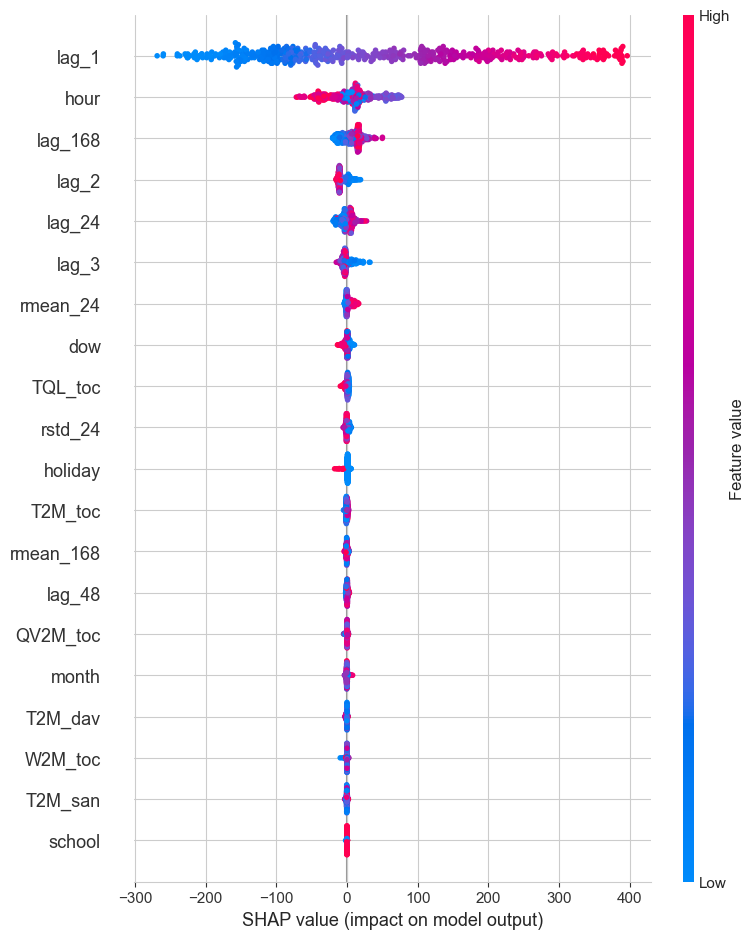

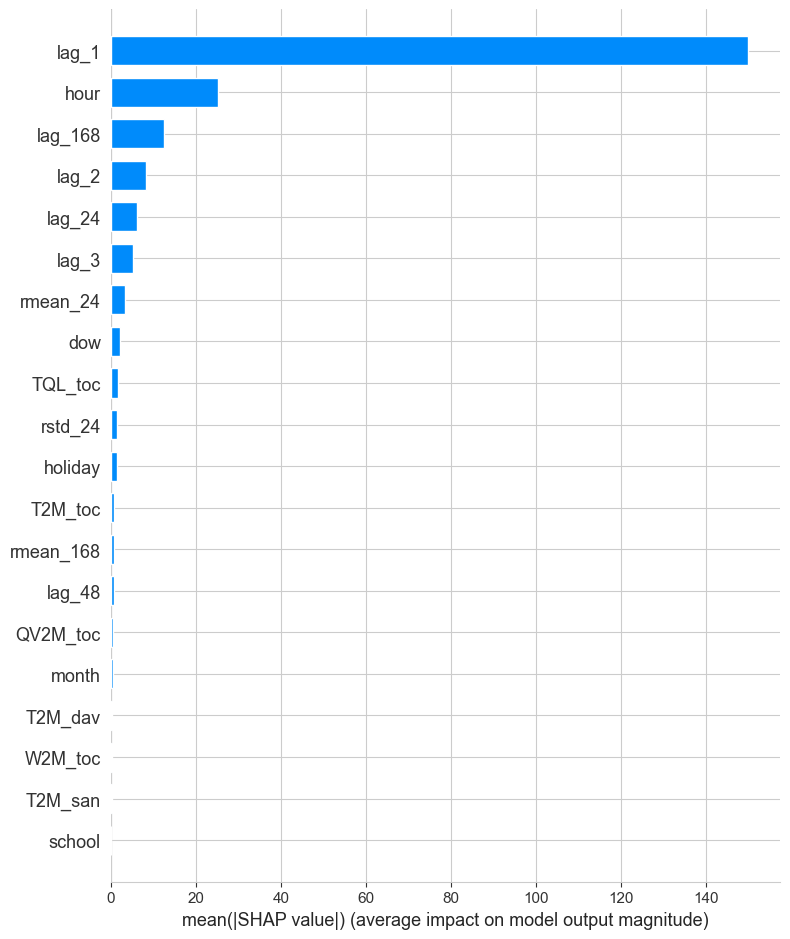

Index with highest load in test: 2020-01-17 14:00:00 | true 1754.9 MW, predicted 1596.1 MW


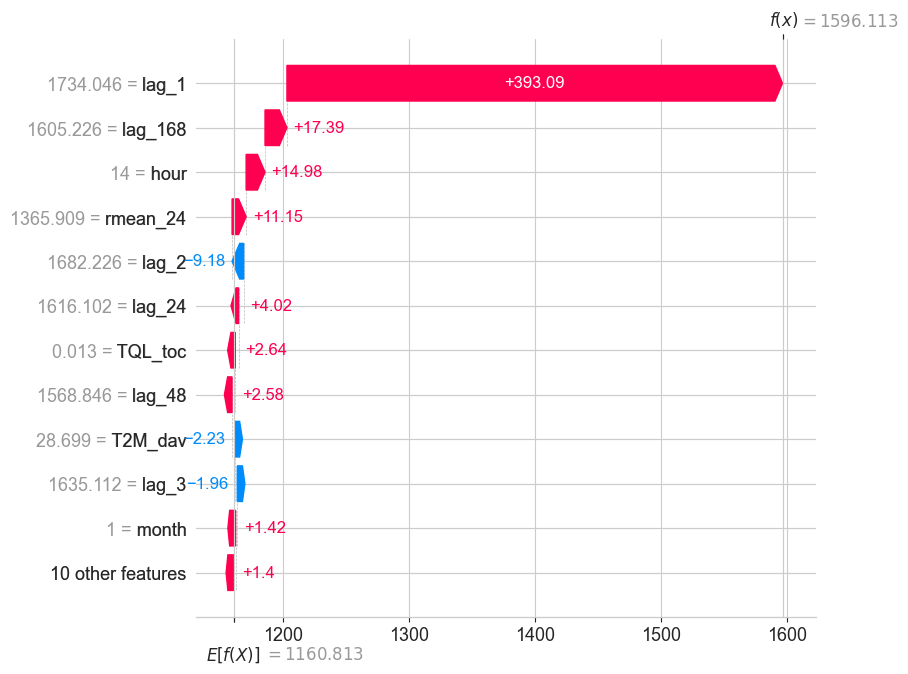

In [15]:
# Subset of X_test for SHAP analysis (to keep compute small)
X_shap = X_test.sample(n=min(500, len(X_test)), random_state=RANDOM_SEED)
# Use TreeExplainer for tree-based models (exact TreeSHAP, path-dependent background)
explainer = shap.TreeExplainer(model)
shap_exp = explainer(X_shap)
shap_values = shap_exp.values
print('Base value E[f(x)]:', round(float(np.ravel(explainer.expected_value)[0]), 1), 'MW')
# Summary plot (beeswarm)
shap.summary_plot(shap_values, X_shap, show=True)
# Bar plot of mean absolute SHAP values
shap.summary_plot(shap_values, X_shap, plot_type='bar', show=True)
# Local explanation for a single interesting point (e.g., highest true load in test)
idx_max = y_test.idxmax()
print('Index with highest load in test:', idx_max, f'| true {y_test[idx_max]:.1f} MW, predicted {yhat[idx_max]:.1f} MW')
x_local = X_test.loc[[idx_max]]
sv_local = explainer(x_local)  # Explanation object, needed by the waterfall plot
shap.plots.waterfall(sv_local[0], max_display=12)

**SHAP global.** El valor base es 1161 MW (la predicción media en TRAIN) y cada barra indica cuántos MW suma o resta cada variable respecto a ese valor.

- **`lag_1` domina** con diferencia (contribuciones de −270 a +390 MW): a 1 h vista, la mejor información es la demanda actual. La relación es casi lineal y monótona (rojo a la derecha, azul a la izquierda).
- **`hour`** es la segunda (±70 MW). Dado `lag_1`, la hora le dice al modelo si la demanda va a subir (rampa de la mañana) o a bajar (tarde-noche).
- **`lag_168` y `lag_24`** aportan el patrón semanal y diario: si la semana pasada a esta hora había mucha demanda, la predicción sube.
- **`lag_2` y `lag_3` tienen signo "al revés"** (valores altos dan contribución negativa). Con `lag_1` fijo, un `lag_2` alto significa que la demanda está bajando, así que el modelo usa la pendiente (momentum). No es un error, pero hay que interpretarlas en conjunto.
- La **meteorología** (`TQL_toc`, `T2M_toc`...) y `holiday` tienen contribuciones pequeñas en media. `school` es prácticamente irrelevante.
- **Waterfall del máximo de TEST (17/01/2020 14 h):** la demanda real es 1755 MW y la predicción 1596 MW, con `lag_1` = 1734 MW aportando +393 MW. La predicción se queda muy por debajo de `lag_1` porque el modelo nunca vio valores por encima de 1645 MW y las hojas de los árboles están acotadas por los objetivos de entrenamiento. SHAP no "explica el error", pero hace visible la saturación: `lag_1` no puede aportar más de ~+390 MW.

In [16]:
# Global importance by group of features (SHAP values are additive, so they can be summed within a group)
feature_groups = {
    'recent lags (t-1..t-3)': ['lag_1', 'lag_2', 'lag_3'],
    'daily/weekly lags': ['lag_24', 'lag_48', 'lag_168'],
    'rolling stats': ['rmean_24', 'rstd_24', 'rmean_168'],
    'calendar': ['hour', 'dow', 'is_weekend', 'month'],
    'holiday/school': CALENDAR_COLS,
    'weather': WEATHER_COLS,
}
sv_df = pd.DataFrame(shap_values, columns=X_shap.columns, index=X_shap.index)
group_imp = pd.Series({g: sv_df[c].sum(axis=1).abs().mean() for g, c in feature_groups.items()}).sort_values(ascending=False)
print('Correlation between lag_1, lag_2, lag_3 and rmean_24 in TEST:')
print(X_test[['lag_1', 'lag_2', 'lag_3', 'rmean_24']].corr().round(3).to_string())
pd.DataFrame({'mean |SHAP| (MW)': group_imp, 'share': group_imp / group_imp.sum()})

Correlation between lag_1, lag_2, lag_3 and rmean_24 in TEST:
          lag_1  lag_2  lag_3  rmean_24
lag_1     1.000  0.955  0.853     0.520
lag_2     0.955  1.000  0.955     0.533
lag_3     0.853  0.955  1.000     0.544
rmean_24  0.520  0.533  0.544     1.000


,mean |SHAP| (MW),share
recent lags (t-1..t-3),143.708,0.741
calendar,25.546,0.132
daily/weekly lags,17.754,0.092
rolling stats,3.514,0.018
weather,1.976,0.010
holiday/school,1.428,0.007


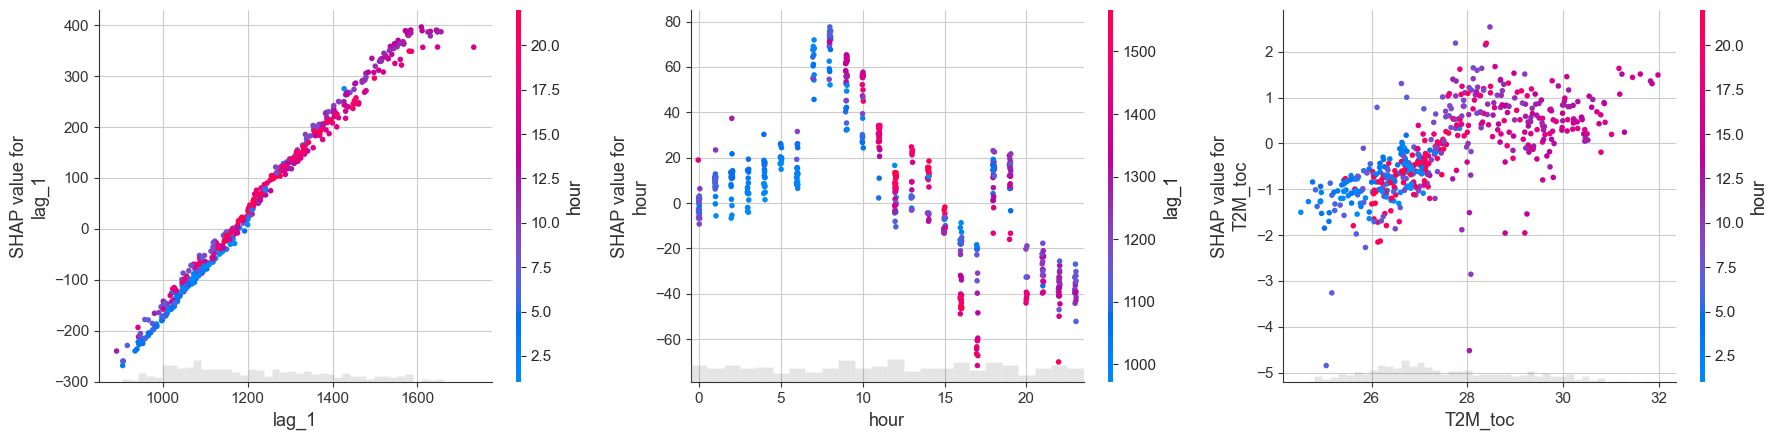

In [17]:
# Dependence plots: how the contribution of a feature changes with its value (colour = interacting feature)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
shap.plots.scatter(shap_exp[:, 'lag_1'], color=shap_exp[:, 'hour'], ax=ax[0], show=False)
shap.plots.scatter(shap_exp[:, 'hour'], color=shap_exp[:, 'lag_1'], ax=ax[1], show=False)
shap.plots.scatter(shap_exp[:, 'T2M_toc'], color=shap_exp[:, 'hour'], ax=ax[2], show=False)
plt.tight_layout()
plt.show()

**Importancia por grupos y dependencias.**

- **Por grupos** (los valores SHAP son aditivos y se pueden sumar), los retardos recientes explican el 74 % de la contribución absoluta media, el calendario el 13 %, los retardos diario/semanal el 9 %, los estadísticos móviles el 2 %, la meteorología el 1 % y festivos/colegios el 0.7 %.
- **Variables correlacionadas:** `lag_1`, `lag_2` y `lag_3` tienen correlaciones de 0.85-0.96, y SHAP reparte el crédito entre ellas de forma algo arbitraria (TreeSHAP *path-dependent*). Por eso tiene más sentido mirar la importancia del grupo que la de cada variable por separado.
- **Dependencia de `lag_1`:** lineal hasta ~1600 MW y plana a partir de ahí (la saturación del punto anterior).
- **Dependencia de `hour`:** máximo a las 7-9 h (+50 a +77 MW, rampa de la mañana) y mínimo a las 15-17 h y por la noche (bajada). Dentro de cada hora, el color muestra la interacción con `lag_1`.
- **Dependencia de `T2M_toc`:** el efecto es creciente con la temperatura (más calor, más demanda), como esperaríamos, pero de solo ±2 MW. Esto **coincide con la intuición** a 1 h: la temperatura explica bien la demanda diaria (EDA), pero su efecto ya está dentro de `lag_1`. En un modelo *day-ahead* debería ser mucho más importante.

2019-10-30 13:00:00 (Wednesday) | true 1225.0 MW, predicted 1482.9 MW, lag_1 = 1467.8 MW


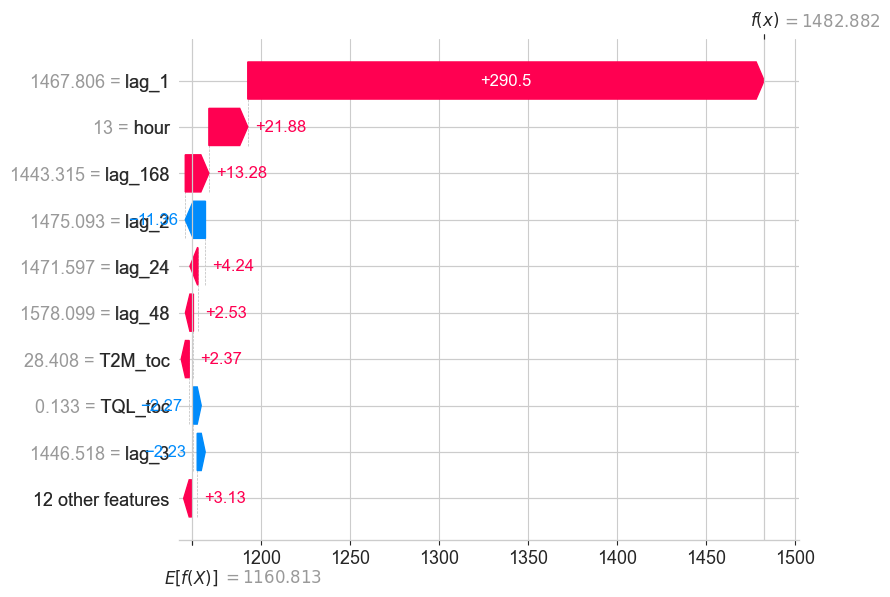

2020-04-14 09:00:00 (Tuesday) | true 1010.0 MW, predicted 1057.0 MW, lag_1 = 989.4 MW


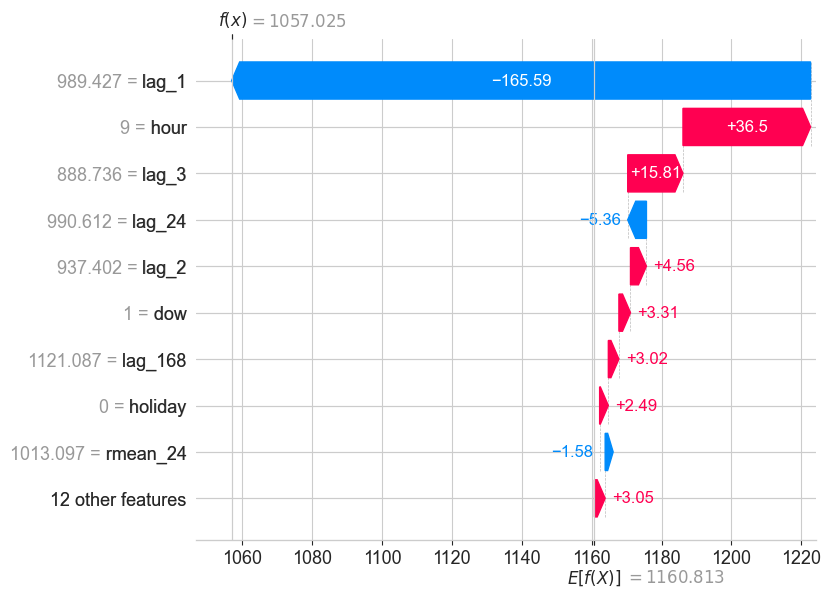

In [18]:
# Two more local explanations: the largest error in TEST and a working-day morning during the lockdown
idx_err = (y_test - yhat).abs().idxmax()
idx_covid = pd.Timestamp('2020-04-14 09:00')
for ts in [idx_err, idx_covid]:
    print(f'{ts} ({ts:%A}) | true {y_test[ts]:.1f} MW, predicted {yhat[ts]:.1f} MW, lag_1 = {X_test.loc[ts, "lag_1"]:.1f} MW')
    shap.plots.waterfall(explainer(X_test.loc[[ts]])[0], max_display=10)

**Explicaciones locales.**

- **Mayor error de TEST (30/10/2019 13 h):** el modelo predice 1483 MW y la demanda real es 1225 MW (caída de 243 MW en una hora). La explicación es la de un mediodía normal: `lag_1` alto (+290 MW) y `hour` = 13 (+22 MW). Ninguna variable contiene información sobre el evento, así que SHAP no puede señalar la causa del error. Explica *por qué el modelo predijo lo que predijo*, no por qué la realidad fue distinta.
- **Martes 14/04/2020 9 h (cuarentena):** predicción 1057 MW, real 1010 MW. `lag_1` = 989 MW empuja hacia abajo (−166 MW), pero `hour` = 9 suma +37 MW y `lag_3` (momentum) +16 MW: el modelo añade la rampa típica de un laborable pre-COVID. La sobreestimación sale de esas dos contribuciones, lo que concuerda con lo visto en la semana de abril de la sección 4.

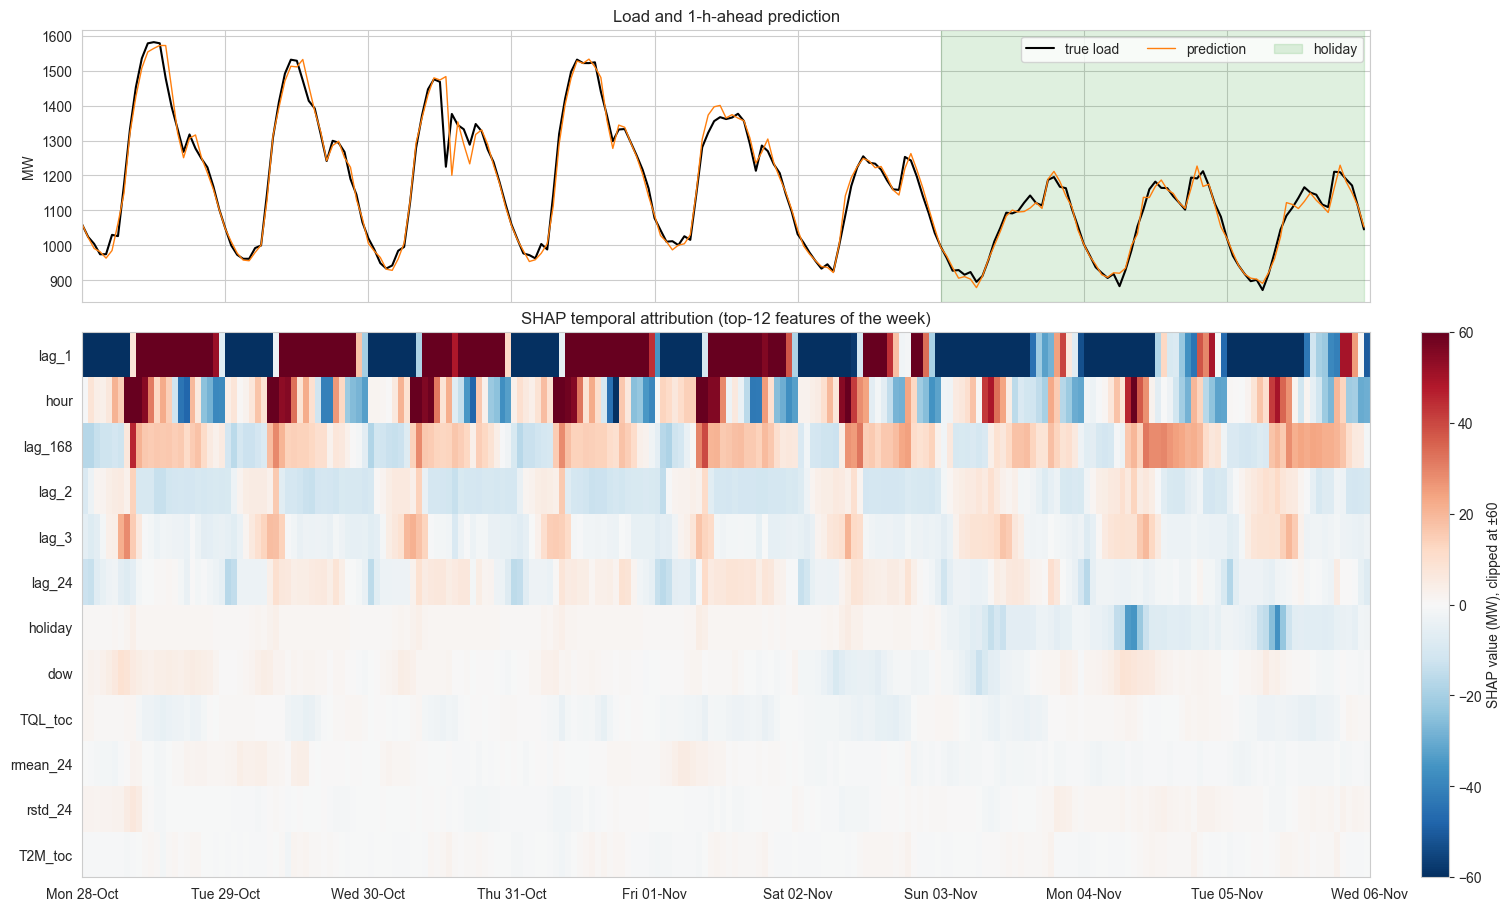

,recent lags (t-1..t-3),daily/weekly lags,rolling stats,calendar,holiday/school,weather
holiday (3-5 Nov),-106.9,6.8,-0.4,3.1,-8.3,-0.4
weekend,-55.0,9.9,-0.9,1.6,1.6,-1.5
working day,52.7,5.7,1.1,9.2,1.2,-0.9


In [19]:
# Temporal SHAP map (same idea as xai_timeseries_shap_heatmap.png): contribution of each feature, hour by hour.
# Week of 28 Oct - 5 Nov 2019: includes a sudden drop on 30 Oct and the national holidays of 3-5 Nov
week = X_test.loc['2019-10-28':'2019-11-05']
sv_week = pd.DataFrame(explainer(week).values, index=week.index, columns=week.columns)
top = sv_week.abs().mean().sort_values(ascending=False).index[:12]
vmax = 60  # MW; lag_1 saturates the scale, the cap makes the other features visible
fig, ax = plt.subplots(2, 1, figsize=(15, 9), sharex=True, gridspec_kw={'height_ratios': [1, 2]}, layout='constrained')
ax[0].plot(week.index, y_test.loc[week.index], color='k', lw=1.5, label='true load')
ax[0].plot(week.index, yhat.loc[week.index], color='C1', lw=1, label='prediction')
hol = (exog_all.loc[week.index, 'holiday'] == 1).values
ax[0].fill_between(week.index, 0, 1, where=hol, transform=ax[0].get_xaxis_transform(), color='C2', alpha=0.15, label='holiday')
ax[0].set_ylabel('MW')
ax[0].legend(loc='upper right', ncol=3)
ax[0].set_title('Load and 1-h-ahead prediction')
x_edges = mdates.date2num(pd.date_range(week.index[0], periods=len(week) + 1, freq='h'))
mesh = ax[1].pcolormesh(x_edges, np.arange(len(top) + 1), sv_week[top].values.T, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax[1].set_yticks(np.arange(len(top)) + 0.5)
ax[1].set_yticklabels(top)
ax[1].invert_yaxis()
ax[1].xaxis.set_major_locator(mdates.DayLocator())
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%a %d-%b'))
ax[1].set_title('SHAP temporal attribution (top-12 features of the week)')
fig.colorbar(mesh, ax=ax[1], label='SHAP value (MW), clipped at ±60', pad=0.01)
plt.show()
# Mean contribution of each group of features by type of day
sv_groups = pd.DataFrame({g: sv_week[c].sum(axis=1) for g, c in feature_groups.items()})
day_type = np.where(hol, 'holiday (3-5 Nov)', np.where(week.index.dayofweek < 5, 'working day', 'weekend'))
sv_groups.groupby(day_type).mean().round(1)

**Mapa temporal de SHAP** (la misma idea que `xai_timeseries_shap_heatmap.png`, pero con valores reales del modelo, hora a hora).

- **`lag_1`** alterna rojo/azul cada día: de día la demanda está por encima del valor base y de noche por debajo. La escala está recortada a ±60 MW para que se vean las demás variables.
- **`hour`** es roja en la rampa de la mañana y azul por la tarde y la noche. Es el "perfil diario" que el modelo añade sobre `lag_1`.
- **Festivos del 3 al 5 de noviembre:** `holiday` se vuelve azul (−8 MW de media, hasta −36 MW en la rampa de la mañana del martes 5), mientras que `lag_168` se vuelve rojo, porque una semana antes, a la misma hora, era un día laborable. El modelo compensa una señal con la otra, que es justo lo que esperaríamos desde el dominio. La tabla resume la contribución media por grupo y tipo de día.
- **Miércoles 30/10:** después de la caída de las 13 h, la predicción de las 14 h baja a ~1200 MW porque `lag_1` ahora es bajo. El modelo "cree" que la caída va a persistir y vuelve a fallar en la recuperación. Es el efecto de depender tanto de `lag_1`.

## Section 6 — Temporal attribution with sliding-window occlusion

Occlusion removes (or perturbs) a contiguous chunk of historical values and observes the impact on the model's prediction for a chosen forecast time. This yields a saliency score per past timestamp.


History length: 168


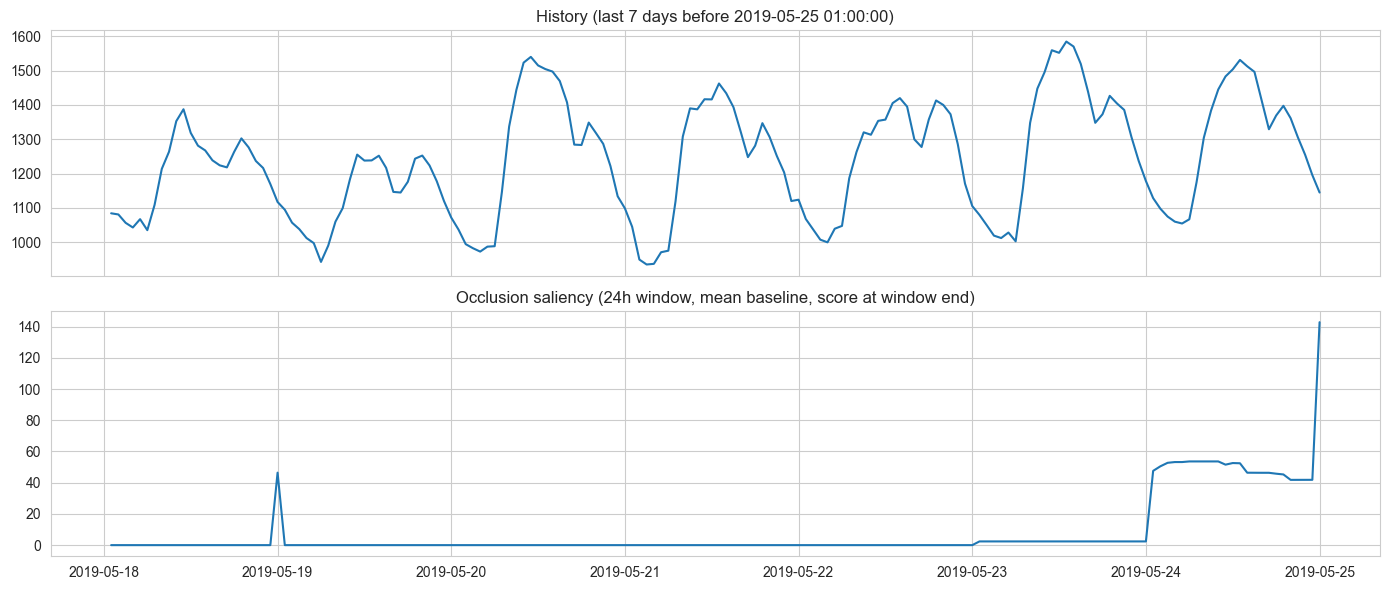

In [20]:
def sliding_window_occlusion(history_series, model, feature_builder, window_size=24, baseline='mean',
                             aggregate='end', signed=False):
    """Compute saliency per time index by occluding a sliding window from history.

    history_series: pandas Series indexed by datetime of past loads (oldest first)
    model: trained model that accepts the feature_builder output
    feature_builder: function that given a history (Series) returns a single-row DataFrame of features
    baseline: 'mean' (history mean), 'interp' (linear interpolation between the window edges), a number, or a
              Series aligned with the history with the replacement values (e.g. the load 24 h earlier)
    aggregate: 'end' gives the score to the last point of each window (template); 'mean' averages, for every
               timestamp, the scores of all the windows that cover it
    signed: if True returns orig_pred - occluded_pred (> 0: that window was pushing the forecast up)
    """
    orig_pred = model.predict(feature_builder(history_series))[0]
    n_hist = len(history_series)
    feats = []
    for i in range(n_hist - window_size + 1):
        hist_copy = history_series.copy()
        # occlude indices i:(i+window_size)
        if isinstance(baseline, pd.Series):
            hist_copy.iloc[i:i + window_size] = baseline.iloc[i:i + window_size].values
        elif baseline == 'mean':
            hist_copy.iloc[i:i + window_size] = history_series.mean()
        elif baseline == 'interp':
            hist_copy.iloc[i:i + window_size] = np.nan
            hist_copy = hist_copy.interpolate(limit_direction='both')
        else:
            hist_copy.iloc[i:i + window_size] = float(baseline)
        feats.append(feature_builder(hist_copy))
    # one batched prediction instead of one call per window
    delta = orig_pred - model.predict(pd.concat(feats))
    if not signed:
        delta = np.abs(delta)
    sal = np.zeros(n_hist)
    counts = np.zeros(n_hist)
    for i, d in enumerate(delta):
        if aggregate == 'end':
            sal[i + window_size - 1] += d
            counts[i + window_size - 1] += 1
        else:
            sal[i:i + window_size] += d
            counts[i:i + window_size] += 1
    sal = np.divide(sal, counts, out=np.zeros(n_hist), where=counts > 0)
    # Earlier positions where no window ends remain zero with aggregate='end'
    return pd.Series(sal, index=history_series.index)


def feature_builder_from_history(history_series, exog=exog_model):
    """Feature row used to forecast the hour right after `history_series` (same features as make_supervised)."""
    # Append a placeholder for the prediction time t and reuse make_supervised without dropping rows.
    # The template version dropped the rows whose target was NaN, so it returned the row of t-2 instead of t
    t = history_series.index[-1] + pd.Timedelta(hours=1)
    s = pd.concat([history_series, pd.Series([np.nan], index=[t])])
    X_tmp, _ = make_supervised(pd.DataFrame({'load': s}), target_col='load', horizon=1, lags=LAGS, exog=exog, dropna=False)
    return X_tmp.iloc[[-1]][X.columns]


def get_history(t, hist_len=168):
    return data['load'].loc[t - pd.Timedelta(hours=hist_len):t - pd.Timedelta(hours=1)]


# Example: first hour of the test set with the last 7 days of history (168 points)
test_idx = X_test.index[0]
history = get_history(test_idx)
print('History length:', len(history))
# Sanity check: the rebuilt features coincide with the row of X_test used by the model
assert np.allclose(feature_builder_from_history(history).values, X_test.loc[[test_idx]].values)
# Guard: only run occlusion if we have enough history
if len(history) >= 24:
    saliency = sliding_window_occlusion(history, model, feature_builder_from_history, window_size=24, baseline='mean')
    # Plot history and saliency
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    # plot both panels with matplotlib (pandas uses its own date units, so sharex with ax2 showed an empty panel)
    ax1.plot(history.index, history.values)
    ax1.set_title(f'History (last 7 days before {test_idx})')
    ax2.plot(saliency.index, saliency.values)
    ax2.set_title('Occlusion saliency (24h window, mean baseline, score at window end)')
    plt.tight_layout()
    plt.show()
else:
    print('Not enough history points to run occlusion example.')

**Occlusion (versión de la plantilla).** Lo primero es comprobar (`assert`) que el `feature_builder` reconstruye exactamente la fila de `X_test`. Con la versión original no era así: devolvía la fila de *t-2* y por tanto la saliencia no correspondía a la predicción que se quería explicar.

En la figura, con ventana de 24 h, línea base = media y la puntuación asignada al **final** de cada ventana:

- Hay un pico grande en la última hora (la ventana contiene *t-1*) y una meseta de ~50 MW para todas las ventanas que terminan en el último día, porque contienen *t-24* y las horas de `rmean_24`.
- Hay un pico aislado el 19/05 a las 0 h: es la ventana que empieza en *t-168*.

Asignar la puntuación al final de la ventana desplaza la atribución en el tiempo (el efecto de *t-168* aparece 23 h más tarde). Por eso en las celdas siguientes promedio, para cada hora, la puntuación de todas las ventanas que la contienen (`aggregate='mean'`) y uso el signo (`signed=True`).

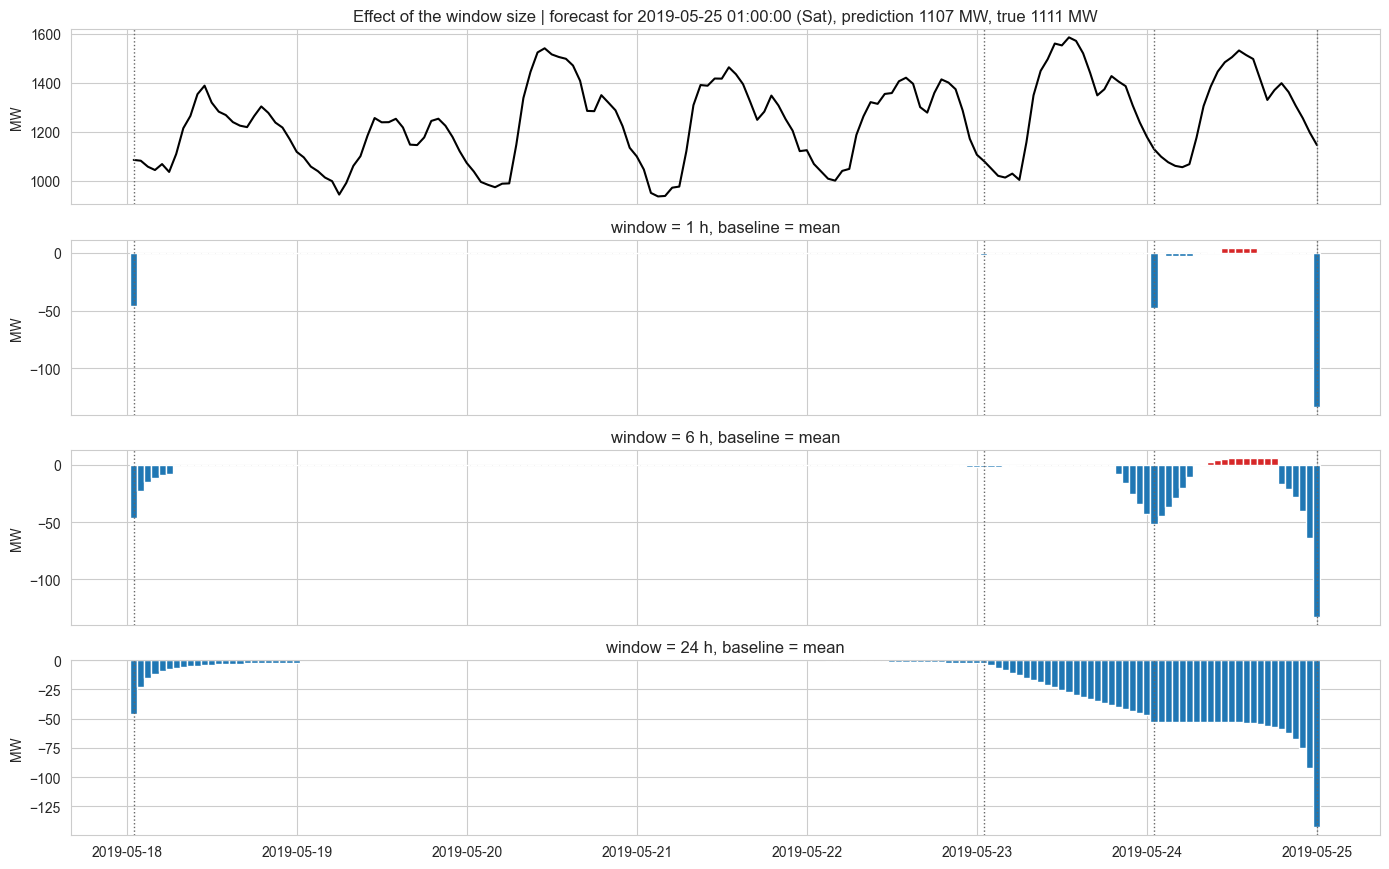

Most salient hours (window = 1 h), expressed as lag w.r.t. the forecast time:
lag_1      133.0
lag_24      47.6
lag_168     46.4
lag_14       4.3
lag_13       4.3
lag_12       4.3


In [21]:
# Different window sizes (signed saliency averaged over all the windows covering each hour)
def mark_lags(ax, t):
    for lag in [1, 24, 48, 168]:
        ax.axvline(t - pd.Timedelta(hours=lag), color='0.4', ls=':', lw=1)


def plot_saliency_grid(t, configs, title):
    hist = get_history(t)
    fig, ax = plt.subplots(len(configs) + 1, 1, figsize=(14, 2.2 * (len(configs) + 1)), sharex=True)
    ax[0].plot(hist.index, hist.values, color='k')
    ax[0].set_title(f'{title} | forecast for {t} ({t:%a}), prediction {model.predict(feature_builder_from_history(hist))[0]:.0f} MW, true {data.loc[t, "load"]:.0f} MW')
    ax[0].set_ylabel('MW')
    mark_lags(ax[0], t)
    out = {}
    for a, (label, kwargs) in zip(ax[1:], configs.items()):
        sal = sliding_window_occlusion(hist, model, feature_builder_from_history, aggregate='mean', signed=True, **kwargs)
        a.bar(sal.index, sal.values, width=1 / 24, color=np.where(sal.values >= 0, 'C3', 'C0'))
        a.set_ylabel('MW')
        a.set_title(label)
        mark_lags(a, t)
        out[label] = sal
    plt.tight_layout()
    plt.show()
    return out


windows = {f'window = {w} h, baseline = mean': dict(window_size=w, baseline='mean') for w in [1, 6, 24]}
sal_windows = plot_saliency_grid(test_idx, windows, 'Effect of the window size')
# Which hours of the history matter? Top-6 hours with the largest |saliency| for window = 1 h
s1 = sal_windows['window = 1 h, baseline = mean']
print('Most salient hours (window = 1 h), expressed as lag w.r.t. the forecast time:')
print(pd.Series(s1.values, index=[f'lag_{int((test_idx - ts) / pd.Timedelta(hours=1))}' for ts in s1.index]).abs().nlargest(6).round(1).to_string())

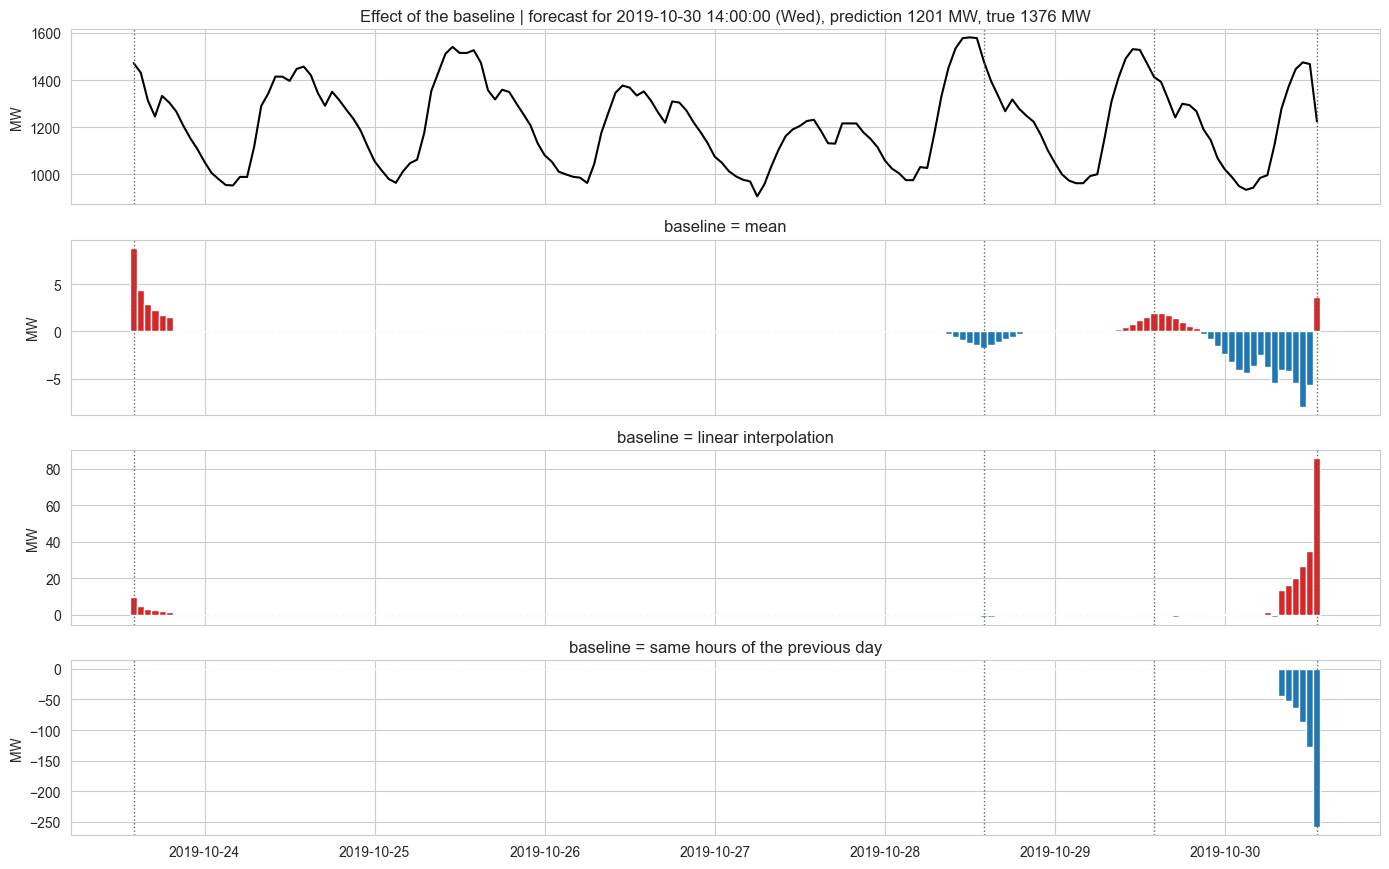

Saliency of the last 6 hours (MW):
                     baseline = mean  baseline = linear interpolation  baseline = same hours of the previous day
datetime                                                                                                        
2019-10-30 08:00:00             -4.1                             13.7                                      -43.7
2019-10-30 09:00:00             -4.2                             16.3                                      -52.1
2019-10-30 10:00:00             -5.4                             20.2                                      -64.6
2019-10-30 11:00:00             -8.0                             26.5                                      -86.3
2019-10-30 12:00:00             -5.7                             35.0                                     -128.4
2019-10-30 13:00:00              3.6                             85.9                                     -258.9


In [22]:
# Different baselines with a 6-hour window: history mean (template), linear interpolation and
# a "seasonal" baseline that replaces the occluded hours by the load observed 24 h earlier
t_b = pd.Timestamp('2019-10-30 14:00')  # one hour after the sudden 240 MW drop of 30 Oct 2019
hist_b = get_history(t_b)
seasonal_b = data['load'].shift(24).loc[hist_b.index]
baselines = {
    'baseline = mean': dict(window_size=6, baseline='mean'),
    'baseline = linear interpolation': dict(window_size=6, baseline='interp'),
    'baseline = same hours of the previous day': dict(window_size=6, baseline=seasonal_b),
}
sal_baselines = plot_saliency_grid(t_b, baselines, 'Effect of the baseline')
print('Saliency of the last 6 hours (MW):')
print(pd.DataFrame({k: v.iloc[-6:] for k, v in sal_baselines.items()}).round(1).to_string())

**Efecto de la ventana.** Con ventana de 1 h, la saliencia se concentra en *t-1* (−133 MW), *t-24* (−48 MW) y *t-168* (−46 MW), más un efecto pequeño (~4 MW) repartido en las últimas 24 h, que corresponde a `rmean_24`/`rstd_24`. Es el "campo receptivo" del modelo y es coherente con SHAP: `lag_1` ≫ `lag_168` ≈ `lag_24` > estadísticos móviles. El signo negativo indica que, a la 1 h de la madrugada, los valores reales están por debajo de la media semanal y empujan la predicción hacia abajo. Con ventanas de 6 h y 24 h la atribución se difumina: es más estable pero pierde resolución. Además, sustituir 24 h por una línea plana crea entradas muy poco realistas.

**Efecto de la línea base** (30/10/2019 14 h, justo después de la caída; predicción 1201 MW, real 1376 MW):

- **Media:** todas las atribuciones son menores de ±9 MW. El valor de la caída (1225 MW) es casi igual a la media semanal, así que "ocultarlo" no cambia nada, y la explicación **no ve** el evento más relevante.
- **Interpolación lineal:** al final de la serie, la interpolación rellena con el último valor anterior a la ventana (de primera hora de la mañana, más bajo). La caída parece entonces empujar la predicción hacia *arriba* (+86 MW), lo cual es engañoso.
- **Mismas horas del día anterior:** la última hora tiene −259 MW. Comparado con un día normal, la caída ha bajado la predicción unos 260 MW, que es casi exactamente el error cometido (1201 frente a 1376 MW). Es la explicación con sentido físico.

**Conclusión:** occlusion es una explicación contrafactual respecto a una línea base, y la elección de la línea base cambia completamente la respuesta. Debe ser realista (dentro de la distribución) y tener significado en el dominio, por ejemplo el perfil típico de esa hora. Además, hay que reportarla siempre junto con la explicación.

## Section 7 — Bootstrap ensemble for predictive variability

Train B bootstrap models (resampling training data with replacement) to approximate variability due to training data sampling. Use their distribution to produce prediction intervals.


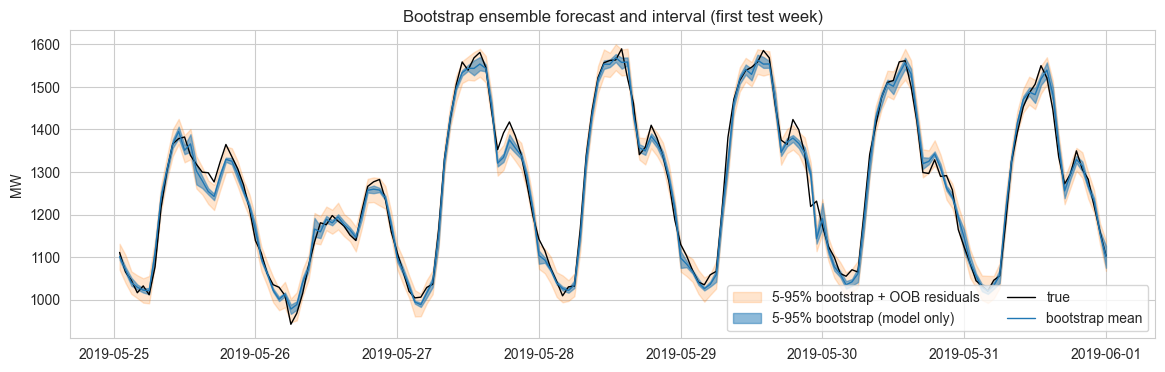

In [23]:
def bootstrap_models(X_train, y_train, base_model, B=20, seed=RANDOM_SEED):
    """Pairs bootstrap: every model is trained on a resample (with replacement) of the TRAIN rows.
    Also returns the out-of-bag (OOB) residuals of every model, i.e. on the rows it did not see."""
    rng = np.random.default_rng(seed)
    models, oob_residuals = [], []
    n = len(X_train)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        m = clone(base_model)
        m.fit(X_train.iloc[idx], y_train.iloc[idx])
        models.append(m)
        oob = np.setdiff1d(np.arange(n), idx)
        oob_residuals.append(y_train.iloc[oob].values - m.predict(X_train.iloc[oob]))
    return models, oob_residuals


# Train B bootstrap models (same HistGradientBoosting configuration as `model`, ~2 s per fit)
B = 20
base = clone(model)
models_b, oob_res = bootstrap_models(X_train, y_train, base, B=B)


# Compute bootstrap predictions for X_test
def bootstrap_predict(models, X):
    preds = np.vstack([m.predict(X) for m in models])  # shape (B, n)
    return preds


preds_b = bootstrap_predict(models_b, X_test)
# Mean and 5th-95th percentile interval
y_mean = preds_b.mean(axis=0)
y_p05 = np.percentile(preds_b, 5, axis=0)
y_p95 = np.percentile(preds_b, 95, axis=0)
# The band above only reflects the variability of the fitted function (epistemic). To get a prediction
# interval we add the noise of the target: each draw = prediction of a random bootstrap model + a random OOB residual
rng = np.random.default_rng(RANDOM_SEED)
pool = np.concatenate(oob_res)
n_draws = 300
draws = preds_b[rng.integers(0, B, size=(n_draws, len(X_test))), np.arange(len(X_test))] + rng.choice(pool, size=(n_draws, len(X_test)))
y_p05_pi = np.percentile(draws, 5, axis=0)
y_p95_pi = np.percentile(draws, 95, axis=0)
# Plot a test week with bootstrap interval
plot_start = X_test.index[0]
plot_end = plot_start + pd.Timedelta(days=7)
mask = (X_test.index >= plot_start) & (X_test.index < plot_end)
plt.figure(figsize=(14, 4))
plt.fill_between(X_test.index[mask], y_p05_pi[mask], y_p95_pi[mask], color='C1', alpha=0.2, label='5-95% bootstrap + OOB residuals')
plt.fill_between(X_test.index[mask], y_p05[mask], y_p95[mask], color='C0', alpha=0.5, label='5-95% bootstrap (model only)')
plt.plot(y_test.index[mask], y_test[mask].values, color='k', lw=1, label='true')
plt.plot(X_test.index[mask], y_mean[mask], color='C0', lw=1, label='bootstrap mean')
plt.legend(ncol=2)
plt.ylabel('MW')
plt.title('Bootstrap ensemble forecast and interval (first test week)')
plt.show()

Mean bootstrap std: 6.6 MW  vs  MAE of the model: 20.4 MW
Spearman correlation between bootstrap std and |error|: 0.292
|OOB residual| 90% quantile: 27.8 MW


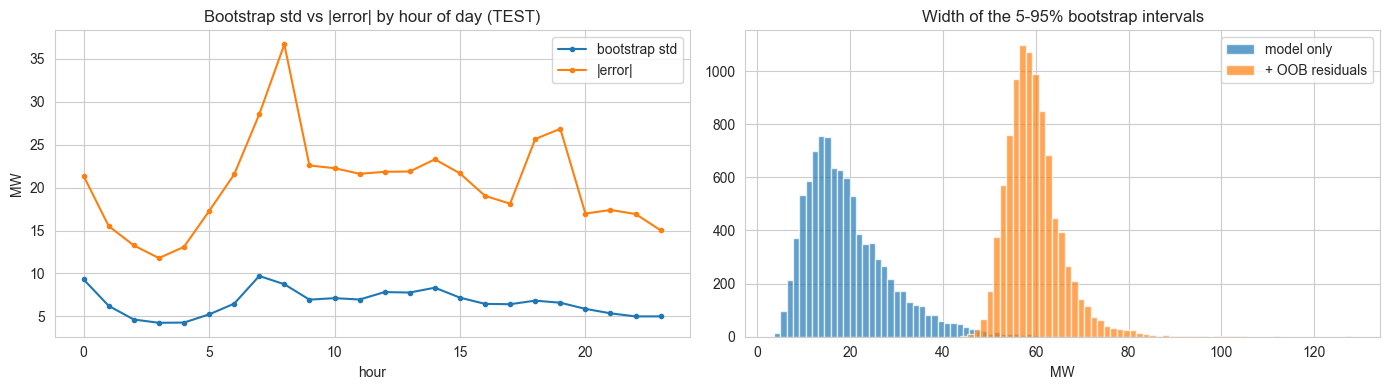

,coverage (nominal 0.90),avg width (MW)
bootstrap 5-95% (model only),0.315,19.547
bootstrap + OOB residuals,0.788,59.600


In [24]:
# Interval widths and empirical coverage of the bootstrap intervals
boot_std = preds_b.std(axis=0)
abs_err = (y_test - yhat).abs().values
boot_summary = pd.DataFrame({
    'coverage (nominal 0.90)': [np.mean((y_test.values >= y_p05) & (y_test.values <= y_p95)),
                                np.mean((y_test.values >= y_p05_pi) & (y_test.values <= y_p95_pi))],
    'avg width (MW)': [np.mean(y_p95 - y_p05), np.mean(y_p95_pi - y_p05_pi)],
}, index=['bootstrap 5-95% (model only)', 'bootstrap + OOB residuals'])
print(f'Mean bootstrap std: {boot_std.mean():.1f} MW  vs  MAE of the model: {abs_err.mean():.1f} MW')
print(f'Spearman correlation between bootstrap std and |error|: {spearmanr(boot_std, abs_err).statistic:.3f}')
print(f'|OOB residual| 90% quantile: {np.quantile(np.abs(pool), 0.9):.1f} MW')
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
by_hour = pd.DataFrame({'bootstrap std': boot_std, '|error|': abs_err}, index=y_test.index).groupby(y_test.index.hour).mean()
by_hour.plot(ax=ax[0], marker='.', title='Bootstrap std vs |error| by hour of day (TEST)')
ax[0].set_xlabel('hour')
ax[0].set_ylabel('MW')
ax[1].hist(y_p95 - y_p05, bins=60, alpha=0.7, label='model only')
ax[1].hist(y_p95_pi - y_p05_pi, bins=60, alpha=0.7, label='+ OOB residuals')
ax[1].set_title('Width of the 5-95% bootstrap intervals')
ax[1].set_xlabel('MW')
ax[1].legend()
plt.tight_layout()
plt.show()
boot_summary

**Comentarios sobre el bootstrap.**

- **El intervalo 5-95 % de los 20 modelos es muy estrecho:** 19.5 MW de ancho medio, con una desviación típica media de 6.6 MW frente a un MAE de 20.4 MW. Solo contiene la demanda real en el **31.5 %** de las horas, cuando nominalmente debería ser el 90 %.
- **Motivo:** el bootstrap mide la incertidumbre **epistémica**, es decir, cuánto cambiaría el modelo con otra muestra de entrenamiento. Con 28 700 horas de entrenamiento el estimador es muy estable. No incluye el ruido **aleatorio** de la demanda (la parte impredecible a 1 h), que es la mayor parte del error. Con un RandomForest sería aún más estrecho, porque el RF ya promedia árboles entrenados sobre muestras bootstrap.
- **Bootstrap + residuos OOB:** si a cada predicción bootstrap le sumo un residuo *out-of-bag*, se obtiene un intervalo de predicción de verdad: ancho de 59.6 MW y cobertura del **78.8 %**, muy parecido al conformal de la sección siguiente.
- **Sigue sin llegar al 90 %:** los residuos OOB son algo optimistas, porque al remuestrear horas sueltas las horas OOB tienen vecinas inmediatas dentro del entrenamiento. Un *block bootstrap* por semanas sería más correcto en series temporales. Además, TEST es más difícil que TRAIN (cambio de distribución).
- **Información útil:** la desviación del bootstrap tiene una correlación de Spearman de 0.29 con el error absoluto y es más alta en las horas difíciles (rampa de las 7-8 h y medianoche). No sirve como intervalo, pero sí como medida relativa de dificultad (por ejemplo, para normalizar un conformal).

## Section 8 — Conformal prediction intervals (inductive residual-based)

Inductive conformal uses residuals on a held-out calibration set to form a distribution of absolute errors; the quantile gives a symmetric interval around point predictions with finite-sample marginal coverage guarantees (under exchangeability).

In [25]:
# Train a fresh model on TRAIN if desired. We'll reuse `model` already trained, but students can retrain here.
# model.fit(X_train, y_train)
# Predict on calibration set and compute residuals
yhat_cal = pd.Series(model.predict(X_cal), index=X_cal.index)
residuals = (y_cal - yhat_cal).abs()


def conformal_q(residuals, alpha=0.1):
    # the usual finite-sample correction: quantile at ceil((n+1)*(1-alpha))/n
    n = len(residuals)
    k = int(np.ceil((n + 1) * (1 - alpha))) - 1
    if k >= n:
        return np.inf  # alpha too small for this calibration size: infinite interval
    return np.partition(residuals, k)[k]


alpha = 0.1
q_alpha = conformal_q(residuals.values, alpha=alpha)
print(f'Conformal q (alpha={alpha}):', q_alpha)
# Build intervals on test
yhat_test = pd.Series(model.predict(X_test), index=X_test.index)
lower = yhat_test - q_alpha
upper = yhat_test + q_alpha
# Evaluate empirical coverage and average width
inside = ((y_test >= lower) & (y_test <= upper)).mean()
avg_width = (upper - lower).mean()
print(f'Coverage on TEST (alpha={alpha}): {inside:.3f}, avg width: {avg_width:.3f}')
# Loop over several alphas
alphas = [0.01, 0.05, 0.1, 0.2, 0.3]
rows = []
for a in alphas:
    q = conformal_q(residuals.values, alpha=a)
    l = yhat_test - q
    u = yhat_test + q
    cov = ((y_test >= l) & (y_test <= u)).mean()
    cov_cal = (residuals <= q).mean()
    rows.append({'alpha': a, 'target 1-alpha': 1 - a, 'q': q, 'coverage CAL': cov_cal, 'coverage TEST': cov,
                 'coverage TEST pre-COVID': ((y_test >= l) & (y_test <= u))[~covid].mean(), 'avg_width': (u - l).mean()})
pd.DataFrame(rows)

Conformal q (alpha=0.1): 30.839428475523846
Coverage on TEST (alpha=0.1): 0.795, avg width: 61.679


,alpha,target 1-alpha,q,coverage CAL,coverage TEST,coverage TEST pre-COVID,avg_width
0,0.01,0.99,67.981,0.99,0.966,0.964,135.962
1,0.05,0.95,39.687,0.95,0.874,0.880,79.374
2,0.10,0.90,30.839,0.90,0.795,0.807,61.679
3,0.20,0.80,22.266,0.80,0.665,0.688,44.532
4,0.30,0.70,17.075,0.70,0.556,0.581,34.151


**Conformal split.** Con α = 0.1 el cuantil de los residuos de calibración es q = 30.8 MW, es decir, una banda de ±30.8 MW (62 MW de ancho, unas 3 veces la del bootstrap). En CAL la cobertura es exactamente 1 − α por construcción, pero en TEST es **0.795** en lugar de 0.90. La tabla muestra el compromiso cobertura/anchura: al bajar α la banda se ensancha (de 34 MW con α = 0.3 a 136 MW con α = 0.01) y la cobertura sube, pero en TEST siempre queda entre 2 y 15 puntos por debajo del objetivo. Incluso sin el periodo COVID la cobertura es solo 0.81, así que el problema no es solo la pandemia.

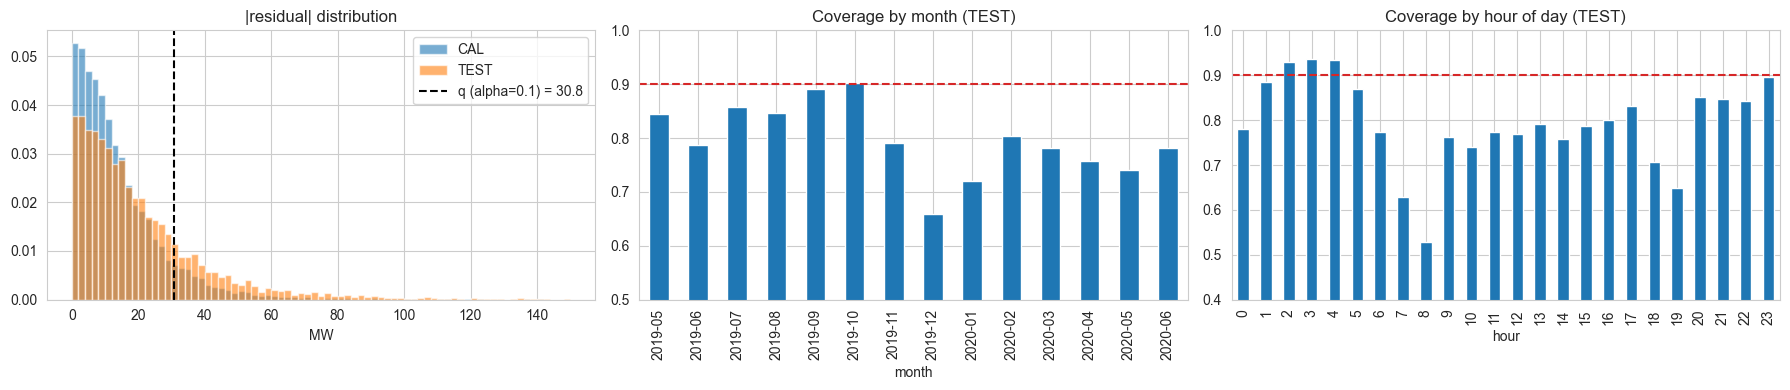

MAE CAL: 14.7 MW | MAE TEST: 20.4 MW
90% quantile of |residual|: CAL 30.8 MW | TEST 44.1 MW


In [26]:
# Why is the TEST coverage below 1 - alpha? Residual distributions and coverage by month / hour of day
res_test_abs = (y_test - yhat_test).abs()
covered = (y_test >= lower) & (y_test <= upper)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(residuals, bins=75, range=(0, 150), density=True, alpha=0.6, label='CAL')
ax[0].hist(res_test_abs, bins=75, range=(0, 150), density=True, alpha=0.6, label='TEST')
ax[0].axvline(q_alpha, color='k', ls='--', label=f'q (alpha={alpha}) = {q_alpha:.1f}')
ax[0].set_title('|residual| distribution')
ax[0].set_xlabel('MW')
ax[0].legend()
cov_m = covered.groupby(covered.index.to_period('M')).mean()
cov_m.plot(kind='bar', ax=ax[1], color='C0')
ax[1].axhline(1 - alpha, color='C3', ls='--')
ax[1].set_ylim(0.5, 1)
ax[1].set_xlabel('month')
ax[1].set_title('Coverage by month (TEST)')
cov_h = covered.groupby(covered.index.hour).mean()
cov_h.plot(kind='bar', ax=ax[2], color='C0')
ax[2].axhline(1 - alpha, color='C3', ls='--')
ax[2].set_ylim(0.4, 1)
ax[2].set_xlabel('hour')
ax[2].set_title('Coverage by hour of day (TEST)')
plt.tight_layout()
plt.show()
print(f'MAE CAL: {mean_absolute_error(y_cal, yhat_cal):.1f} MW | MAE TEST: {res_test_abs.mean():.1f} MW')
print(f'90% quantile of |residual|: CAL {residuals.quantile(0.9):.1f} MW | TEST {res_test_abs.quantile(0.9):.1f} MW')

**¿Por qué falla la garantía?** La garantía del conformal es marginal y supone que los datos de CAL y TEST son intercambiables. Aquí no lo son:

- **TEST es más difícil:** el MAE pasa de 14.7 MW en CAL a 20.4 MW en TEST, y el cuantil 90 % del error de 30.8 a 44.1 MW. El histograma de TEST tiene la cola más pesada.
- **Por mes:** la cobertura es buena de julio a octubre de 2019 (0.85-0.90) y se hunde en diciembre y enero (0.66 y 0.72), por los picos récord y las fiestas, y durante el COVID (0.74-0.78).
- **Por hora:** de madrugada la banda sobra (0.93) y en las rampas falta (0.53 a las 8 h, 0.65 a las 19 h). Una cobertura marginal del 90 % no implica un 90 % condicional a cada hora, porque el error es heterocedástico.

In [27]:
# (a) Mondrian conformal by hour of day: one quantile per hour -> handles the heteroscedasticity across the day
q_hour = residuals.groupby(residuals.index.hour).apply(lambda r: conformal_q(r.values, alpha=alpha))
q_mondrian = pd.Series(q_hour.reindex(y_test.index.hour).values, index=y_test.index)


# (b) Online conformal. In operation the true load arrives one hour after the forecast, so its residual can be
# added to the calibration scores, keeping only the last `window` hours (sliding calibration set). With gamma > 0
# this becomes Adaptive Conformal Inference (Gibbs & Candes, 2021): alpha_{t+1} = alpha_t + gamma * (alpha - err_t),
# which keeps the long-run coverage close to 1 - alpha even under distribution shift.
def online_conformal(res_cal, res_test, alpha=0.1, gamma=0.0, window=None):
    r_test = np.asarray(res_test)
    scores = np.concatenate([np.asarray(res_cal), r_test])
    n_cal = len(res_cal)
    alpha_t = alpha
    q_path = np.empty(len(r_test))
    for i in range(len(r_test)):
        start = 0 if window is None else max(0, n_cal + i - window)
        window_scores = scores[start:n_cal + i]
        q = 0.0 if alpha_t >= 1 else (conformal_q(window_scores, alpha=alpha_t) if alpha_t > 0 else np.inf)
        if not np.isfinite(q):
            q = window_scores.max()  # cap: never wider than the largest residual in the window
        q_path[i] = q
        alpha_t += gamma * (alpha - float(r_test[i] > q))
    return pd.Series(q_path, index=getattr(res_test, 'index', None))


WINDOW = 24 * 7 * 8  # 8 weeks
q_roll = online_conformal(residuals.values, res_test_abs, alpha=alpha, window=WINDOW)
q_aci = online_conformal(residuals.values, res_test_abs, alpha=alpha, gamma=0.005, window=WINDOW)

# (c) Quantile regression + Conformalized Quantile Regression (CQR, Romano et al. 2019). Two HistGB models with the
# pinball loss estimate the 5% and 95% quantiles directly, so the width depends on x (heteroscedastic). CQR calibrates
# them on CAL with the score max(q_lo - y, y - q_hi); the same score can be used with ACI (adaptive CQR)
qr_lo = clone(model).set_params(loss='quantile', quantile=alpha / 2).fit(X_train, y_train)
qr_hi = clone(model).set_params(loss='quantile', quantile=1 - alpha / 2).fit(X_train, y_train)
lo_qr = pd.Series(qr_lo.predict(X_test), index=X_test.index)
hi_qr = pd.Series(qr_hi.predict(X_test), index=X_test.index)
lo_qr_cal, hi_qr_cal = qr_lo.predict(X_cal), qr_hi.predict(X_cal)
scores_cal = np.maximum(lo_qr_cal - y_cal.values, y_cal.values - hi_qr_cal)
scores_test = np.maximum(lo_qr - y_test, y_test - hi_qr)
q_cqr = conformal_q(scores_cal, alpha=alpha)
q_cqr_aci = online_conformal(scores_cal, scores_test, alpha=alpha, gamma=0.005, window=WINDOW)
print(f'Raw quantile regression: coverage CAL {np.mean((y_cal.values >= lo_qr_cal) & (y_cal.values <= hi_qr_cal)):.3f}, '
      f'CQR correction q = {q_cqr:.1f} MW')

intervals = {
    'Bootstrap 5-95% (model only)': (y_p05, y_p95),
    'Bootstrap + OOB residuals': (y_p05_pi, y_p95_pi),
    'Split conformal (template)': (lower, upper),
    'Mondrian conformal (hour)': (yhat_test - q_mondrian, yhat_test + q_mondrian),
    'Quantile regression (HistGB)': (lo_qr, hi_qr),
    'CQR': (lo_qr - q_cqr, hi_qr + q_cqr),
    'Online conformal (last 8 weeks)': (yhat_test - q_roll, yhat_test + q_roll),
    'Adaptive conformal (ACI, 8 weeks)': (yhat_test - q_aci, yhat_test + q_aci),
    'Adaptive CQR (ACI, 8 weeks)': (lo_qr - q_cqr_aci, hi_qr + q_cqr_aci),
}


def interval_report(lo, hi):
    lo = pd.Series(np.asarray(lo), index=y_test.index)
    hi = pd.Series(np.asarray(hi), index=y_test.index)
    cov = (y_test >= lo) & (y_test <= hi)
    by_hour = cov.groupby(cov.index.hour).mean()
    return {'coverage': cov.mean(), 'coverage pre-COVID': cov[~covid].mean(), 'coverage COVID': cov[covid].mean(),
            'worst hour': by_hour.min(), 'best hour': by_hour.max(), 'avg width (MW)': (hi - lo).mean()}


interval_table = pd.DataFrame({name: interval_report(*lh) for name, lh in intervals.items()}).T
interval_table

Raw quantile regression: coverage CAL 0.805, CQR correction q = 6.6 MW


,coverage,coverage pre-COVID,coverage COVID,worst hour,best hour,avg width (MW)
Bootstrap 5-95% (model only),0.315,0.336,0.256,0.211,0.376,19.547
Bootstrap + OOB residuals,0.788,0.802,0.748,0.539,0.940,59.600
Split conformal (template),0.795,0.807,0.761,0.529,0.937,61.679
Mondrian conformal (hour),0.782,0.797,0.740,0.694,0.882,60.410
Quantile regression (HistGB),0.721,0.725,0.710,0.526,0.817,60.962
CQR,0.825,0.828,0.819,0.694,0.895,74.062
Online conformal (last 8 weeks),0.899,0.898,0.903,0.672,0.975,89.948
"Adaptive conformal (ACI, 8 weeks)",0.900,0.902,0.893,0.659,0.987,89.643
"Adaptive CQR (ACI, 8 weeks)",0.900,0.901,0.896,0.817,0.957,91.288


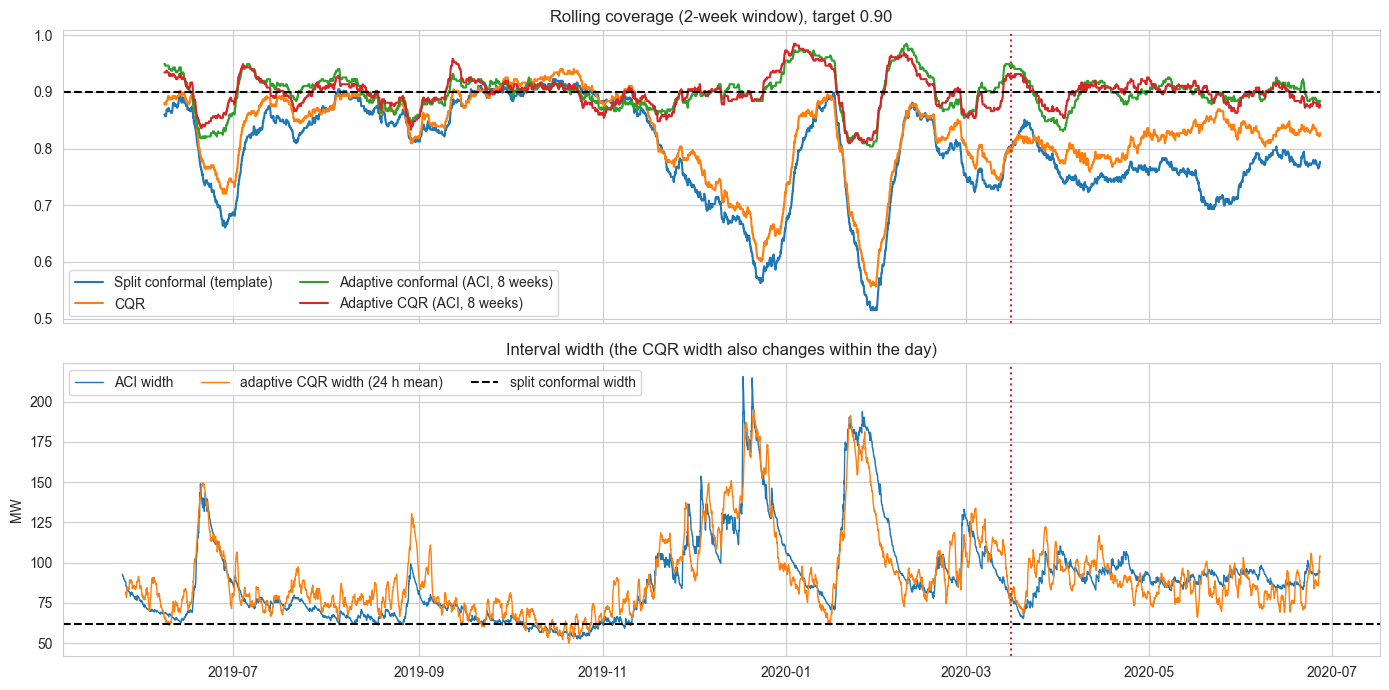

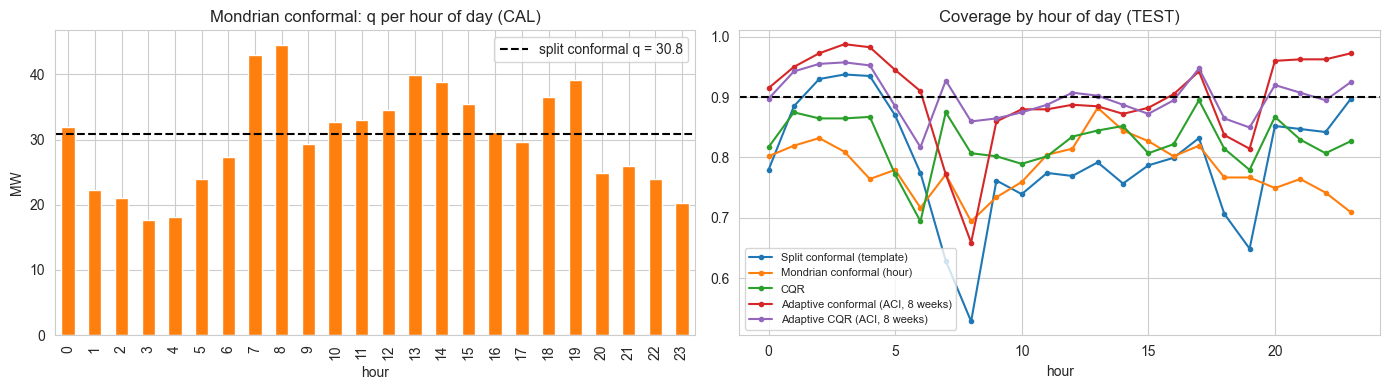

In [28]:
# Rolling coverage over the TEST period and width of the adaptive interval
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for name in ['Split conformal (template)', 'CQR', 'Adaptive conformal (ACI, 8 weeks)', 'Adaptive CQR (ACI, 8 weeks)']:
    lo, hi = intervals[name]
    cov = ((y_test >= lo) & (y_test <= hi)).astype(float)
    ax[0].plot(cov.rolling(24 * 14).mean(), label=name)
ax[0].axhline(1 - alpha, color='k', ls='--')
ax[0].axvline(COVID_START, color='C3', ls=':')
ax[0].set_title('Rolling coverage (2-week window), target 0.90')
ax[0].legend(ncol=2, loc='lower left')
ax[1].plot(2 * q_aci, label='ACI width', lw=1)
cqr_width = intervals['Adaptive CQR (ACI, 8 weeks)'][1] - intervals['Adaptive CQR (ACI, 8 weeks)'][0]
ax[1].plot(cqr_width.rolling(24).mean(), label='adaptive CQR width (24 h mean)', lw=1)
ax[1].axhline(2 * q_alpha, color='k', ls='--', label='split conformal width')
ax[1].axvline(COVID_START, color='C3', ls=':')
ax[1].set_ylabel('MW')
ax[1].set_title('Interval width (the CQR width also changes within the day)')
ax[1].legend(ncol=3)
plt.tight_layout()
plt.show()
# Mondrian conformal: quantile per hour of day, and coverage per hour of the different methods
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
q_hour.plot(kind='bar', ax=ax[0], color='C1')
ax[0].axhline(q_alpha, color='k', ls='--', label=f'split conformal q = {q_alpha:.1f}')
ax[0].set_title('Mondrian conformal: q per hour of day (CAL)')
ax[0].set_xlabel('hour')
ax[0].set_ylabel('MW')
ax[0].legend()
cov_by_hour = pd.DataFrame({name: ((y_test >= intervals[name][0]) & (y_test <= intervals[name][1])).groupby(y_test.index.hour).mean()
                            for name in ['Split conformal (template)', 'Mondrian conformal (hour)', 'CQR',
                                         'Adaptive conformal (ACI, 8 weeks)', 'Adaptive CQR (ACI, 8 weeks)']})
cov_by_hour.plot(ax=ax[1], marker='.')
ax[1].axhline(1 - alpha, color='k', ls='--')
ax[1].set_title('Coverage by hour of day (TEST)')
ax[1].set_xlabel('hour')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Variantes de conformal.**

- **Mondrian por hora:** se calcula un cuantil por hora del día (de 17.5 MW a las 3 h a 44 MW a las 8 h). Con el mismo ancho medio (60 MW), la cobertura por hora es mucho más homogénea: la peor hora pasa de 0.53 a 0.69. Resuelve la heterocedasticidad, pero no el cambio de distribución (la cobertura marginal sigue en 0.78).
- **Regresión cuantílica y CQR:** dos HistGB con pérdida *pinball* estiman directamente los cuantiles del 5 % y del 95 %, así que el ancho de la banda depende de la hora y del estado del sistema. Sin calibrar se quedan cortos (cobertura 0.805 en CAL y 0.721 en TEST). CQR (*conformalized quantile regression*) los corrige con los residuos de calibración, ensanchando la banda 6.6 MW por cada lado, y llega a 0.825 en TEST con 74 MW de ancho medio. Es la mejor de las variantes estáticas, pero sigue sufriendo el cambio de distribución.
- **Conformal online (ventana de 8 semanas) y ACI:** como la demanda real se conoce una hora después, los residuos de TEST se pueden ir incorporando al conjunto de calibración. La ventana móvil por sí sola ya devuelve la cobertura a 0.899, y ACI (que además corrige α_t según los fallos recientes) la deja en **0.900**, también durante el COVID (0.89-0.90). El precio es una banda más ancha (~90 MW de media), que se ensancha automáticamente en diciembre-febrero (hasta ~215 MW) y se estabiliza en el periodo COVID. En la gráfica de cobertura móvil, el conformal estático baja hasta 0.5 en diciembre-enero mientras que ACI se mantiene en torno a 0.9.
- **CQR adaptativo (CQR + ACI):** junta las dos ideas: el ancho depende de la hora (CQR) y el nivel se corrige con los fallos recientes (ACI). Mantiene la cobertura en 0.900 (0.896 en el periodo COVID) con un ancho medio parecido (91 MW), pero la peor hora sube de 0.66 a **0.82**. Es el método con la cobertura por hora más homogénea y el que usaría en operación.
- **Limitación:** ACI garantiza la cobertura media a largo plazo, no la de cada hora. Incluso con CQR adaptativo la rampa de las 6-7 h queda por debajo del 90 %. Un siguiente paso sería normalizar el score por una medida de dificultad, como la desviación del bootstrap.

**Comparación bootstrap vs. conformal:** el bootstrap "puro" no es un intervalo de predicción (31 %). Con los residuos añadidos se comporta casi igual que el conformal split (79 % frente a 80 %, ~60 MW). La diferencia de fondo es que el conformal tiene una garantía en muestra finita (bajo intercambiabilidad) y además se puede hacer adaptativo de forma sencilla.

## Section 9 — Using intervals for anomaly flagging

Flag times where true load lies outside conformal intervals — potentially anomalous events requiring operator attention.


Number of anomalies in TEST: 1965 (20.5% of the hours)


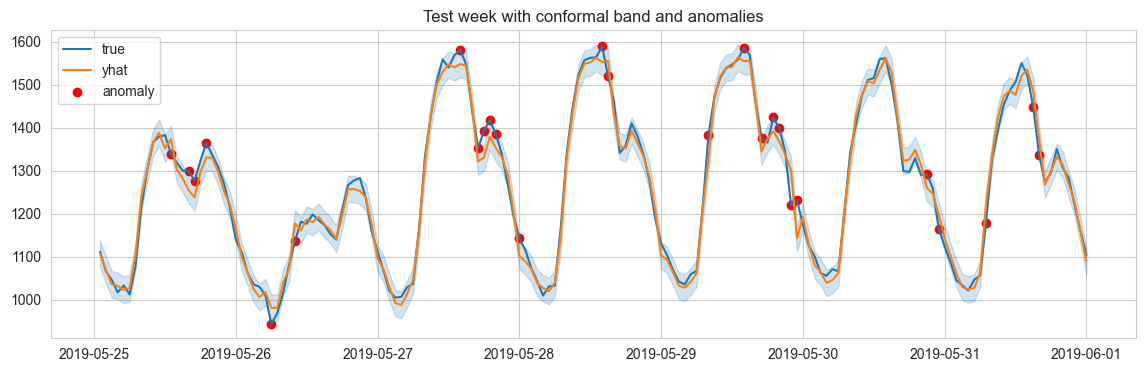

,y_true,yhat,lower,upper,anomaly
datetime,,,,,
2019-05-25 13:00:00,1339.094,1373.198,1342.359,1404.038,True
2019-05-25 16:00:00,1298.431,1254.496,1223.657,1285.336,True
2019-05-25 17:00:00,1276.797,1237.571,1206.732,1268.411,True
2019-05-25 19:00:00,1364.775,1330.652,1299.812,1361.491,True
2019-05-26 06:00:00,942.462,980.735,949.896,1011.575,True
2019-05-26 10:00:00,1135.366,1176.998,1146.158,1207.837,True
2019-05-27 14:00:00,1581.063,1547.586,1516.746,1578.425,True
2019-05-27 17:00:00,1352.557,1321.215,1290.376,1352.055,True
2019-05-27 18:00:00,1391.854,1330.200,1299.361,1361.040,True


In [29]:
# Using alpha chosen earlier
yhat_test = pd.Series(model.predict(X_test), index=X_test.index)
lower = yhat_test - q_alpha
upper = yhat_test + q_alpha
anomaly = ~((y_test >= lower) & (y_test <= upper))
anomalies = pd.DataFrame({'y_true': y_test, 'yhat': yhat_test, 'lower': lower, 'upper': upper, 'anomaly': anomaly})
print('Number of anomalies in TEST:', anomalies['anomaly'].sum(), f'({anomalies["anomaly"].mean():.1%} of the hours)')
# Plot a test week with anomalies marked
try:
    mask = (X_test.index >= X_test.index[0]) & (X_test.index < X_test.index[0] + pd.Timedelta(days=7))
    plt.figure(figsize=(14, 4))
    plt.plot(anomalies.loc[mask].index, anomalies.loc[mask, 'y_true'], label='true')
    plt.plot(anomalies.loc[mask].index, anomalies.loc[mask, 'yhat'], label='yhat')
    plt.fill_between(anomalies.loc[mask].index, anomalies.loc[mask, 'lower'], anomalies.loc[mask, 'upper'], color='C0', alpha=0.2)
    # mark anomalies
    an_idx = anomalies.loc[mask & anomalies['anomaly']].index
    plt.scatter(an_idx, anomalies.loc[an_idx, 'y_true'], color='red', label='anomaly')
    plt.legend()
    plt.title('Test week with conformal band and anomalies')
    plt.show()
except Exception as e:
    print('Could not plot anomalies:', e)
# Print a small table of anomalies (timestamp, y_true, yhat, lower, upper)
anomalies[anomalies['anomaly']].head(20)

**Con la regla de la plantilla (α = 0.1) salen 1965 "anomalías", el 20.5 % de las horas.** Este criterio no sirve para alarmas. Aunque el intervalo estuviera perfectamente calibrado, marcaría el 10 % de las horas por construcción (≈ 2-3 alarmas al día, unas 960 al año), y con la infracobertura que hemos visto marca el doble. En la primera semana de test los puntos rojos son errores normales en picos y rampas, no eventos. Para detectar anomalías hace falta un α mucho más pequeño y un umbral que se adapte al régimen actual.

In [30]:
# Stricter and adaptive alarm: alpha = 1% with the residuals of the last 8 weeks as calibration set
alpha_anom = 0.01
res_signed = y_test - yhat_test
q_anom = online_conformal(residuals.values, res_test_abs, alpha=alpha_anom, window=WINDOW)
flag = res_test_abs > q_anom
print(f'alpha = {alpha_anom}: {flag.sum()} flagged hours ({flag.mean():.2%} of TEST); '
      f'with the static split-conformal quantile there would be {(res_test_abs > conformal_q(residuals.values, alpha_anom)).sum()}')
# Group consecutive flagged hours into events and describe them
event_id = (flag != flag.shift()).cumsum()[flag]
ev = pd.DataFrame({'residual': res_signed[flag], 'y_true': y_test[flag], 'event': event_id})
events = ev.groupby('event').agg(start=('residual', lambda s: s.index.min()), hours=('residual', 'size'),
                                 max_abs_residual=('residual', lambda s: s.abs().max()),
                                 min_residual=('residual', 'min'), max_residual=('residual', 'max'), max_true=('y_true', 'max'))
events['weekday'] = events['start'].dt.day_name()
events['holiday'] = exog_all.loc[events['start'], 'holiday'].values
events['period'] = np.where(events['start'] >= COVID_START, 'COVID', 'pre-COVID')


def event_type(r):
    if r['min_residual'] < 0 < r['max_residual']:
        return 'drop + recovery'
    if r['max_true'] > y_train.max():
        return 'above TRAIN max'
    return 'under-forecast' if r['max_residual'] > 0 else 'over-forecast'


events['type'] = events.apply(event_type, axis=1)
print(f'{len(events)} events')
print(events.groupby(['type', 'period']).size().unstack(fill_value=0).to_string())
events.sort_values('max_abs_residual', ascending=False).drop(columns=['min_residual', 'max_residual']).head(12).reset_index(drop=True)

alpha = 0.01: 99 flagged hours (1.03% of TEST); with the static split-conformal quantile there would be 328
70 events
period           COVID  pre-COVID
type                             
above TRAIN max      0         11
drop + recovery      1          4
over-forecast        8         18
under-forecast       1         27


,start,hours,max_abs_residual,max_true,weekday,holiday,period,type
0,2019-10-30 13:00:00,2,257.851,1375.953,Wednesday,0,pre-COVID,drop + recovery
1,2019-07-13 06:00:00,1,198.691,1224.936,Saturday,0,pre-COVID,under-forecast
2,2019-11-23 06:00:00,2,165.278,1077.442,Saturday,0,pre-COVID,drop + recovery
3,2020-01-17 18:00:00,4,163.781,1630.244,Friday,0,pre-COVID,under-forecast
4,2020-01-17 13:00:00,3,158.769,1754.882,Friday,0,pre-COVID,above TRAIN max
5,2020-01-26 07:00:00,1,155.258,987.821,Sunday,0,pre-COVID,over-forecast
6,2020-02-28 11:00:00,5,143.390,1738.039,Friday,0,pre-COVID,above TRAIN max
7,2019-08-28 13:00:00,1,142.834,1420.956,Wednesday,0,pre-COVID,over-forecast
8,2019-12-17 13:00:00,2,140.436,1721.516,Tuesday,0,pre-COVID,above TRAIN max
9,2020-03-26 09:00:00,1,139.116,1065.494,Thursday,0,COVID,over-forecast


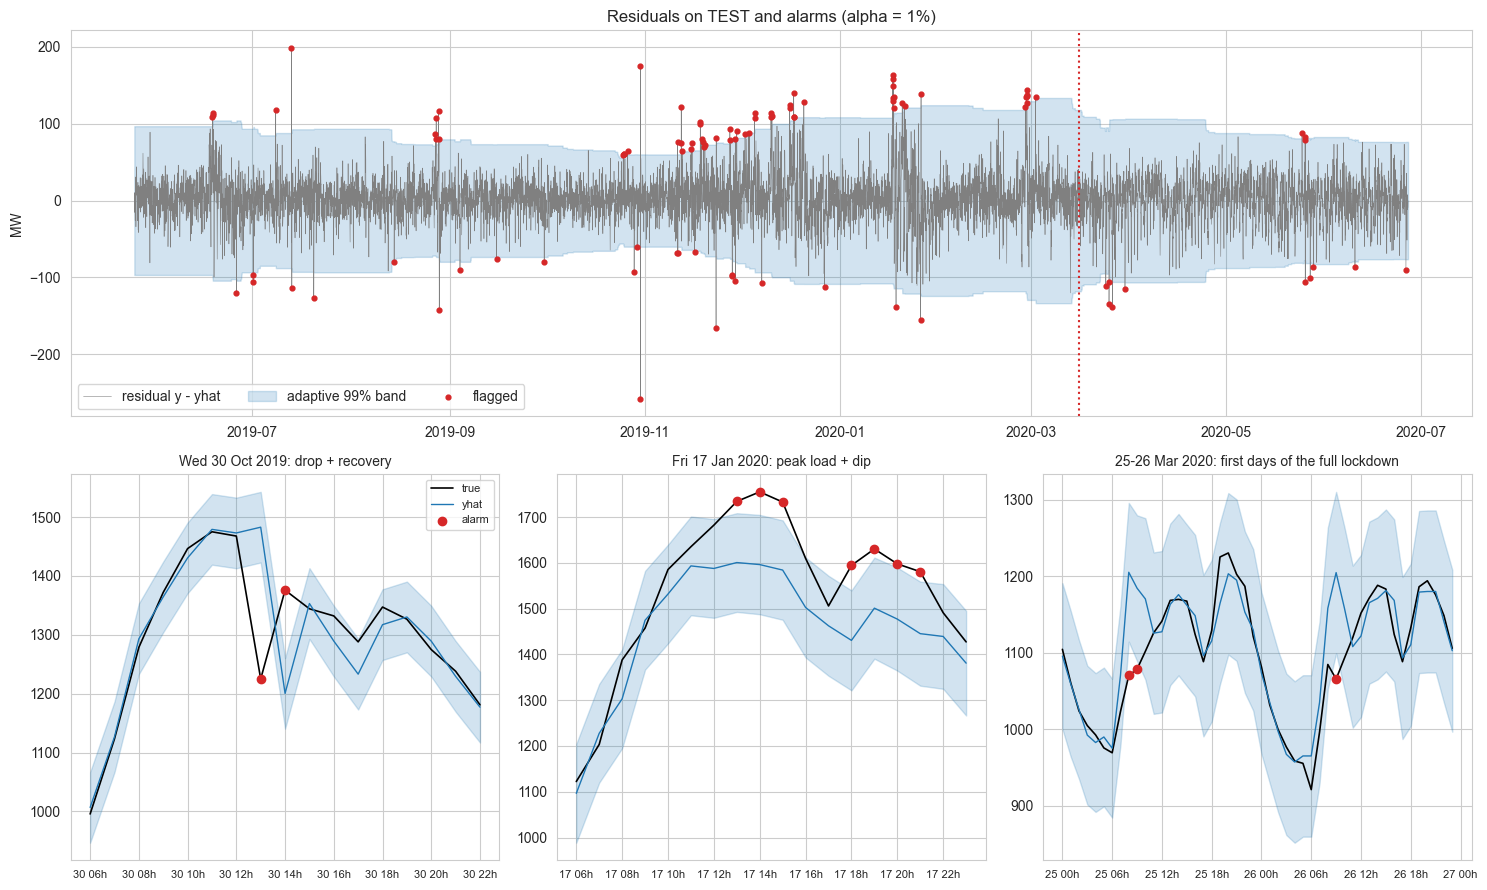

In [31]:
# Residuals over the whole TEST period with the adaptive 99% threshold, and three of the flagged events
fig = plt.figure(figsize=(15, 9))
ax0 = fig.add_subplot(2, 1, 1)
ax0.plot(res_signed.index, res_signed.values, color='0.5', lw=0.4, label='residual y - yhat')
ax0.fill_between(q_anom.index, -q_anom, q_anom, color='C0', alpha=0.2, label='adaptive 99% band')
ax0.scatter(res_signed.index[flag], res_signed[flag], color='C3', s=12, zorder=3, label='flagged')
ax0.axvline(COVID_START, color='C3', ls=':')
ax0.set_ylabel('MW')
ax0.set_title('Residuals on TEST and alarms (alpha = 1%)')
ax0.legend(ncol=3, loc='lower left')
zooms = [('2019-10-30 06:00', '2019-10-30 22:00', 'Wed 30 Oct 2019: drop + recovery'),
         ('2020-01-17 06:00', '2020-01-17 23:00', 'Fri 17 Jan 2020: peak load + dip'),
         ('2020-03-25 00:00', '2020-03-26 23:00', '25-26 Mar 2020: first days of the full lockdown')]
for j, (a, b, title) in enumerate(zooms):
    ax = fig.add_subplot(2, 3, 4 + j)
    sl = slice(a, b)
    ax.fill_between(yhat_test.loc[sl].index, (yhat_test - q_anom).loc[sl], (yhat_test + q_anom).loc[sl], color='C0', alpha=0.2)
    ax.plot(y_test.loc[sl], color='k', lw=1.2, label='true')
    ax.plot(yhat_test.loc[sl], color='C0', lw=1, label='yhat')
    f = flag.loc[sl]
    ax.scatter(f.index[f], y_test.loc[sl][f], color='C3', zorder=3, label='alarm')
    ax.set_title(title, fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %Hh'))
    ax.tick_params(axis='x', labelsize=8)
    if j == 0:
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Revisión de las anomalías (α = 1 %, conformal online con ventana de 8 semanas).** Quedan 99 horas marcadas (1.03 %, justo lo esperado), agrupadas en 70 eventos. Con el cuantil estático serían 328, concentradas en diciembre-enero. Los eventos se pueden clasificar así:

- **Probables eventos reales de red (caída + recuperación), 5 eventos.** El 30/10/2019 a las 13 h la demanda cae 243 MW en una hora y se recupera a la siguiente. El 23/11/2019 a las 6 h pasa de 1044 a 903 y vuelve a 1077 MW. Una caída instantánea con recuperación inmediata encaja con un disparo de generación o de carga, un deslastre o un fallo de telemedida. El modelo falla dos veces (en la caída y en la recuperación) por depender de `lag_1`.
- **Fallos del modelo por extrapolación (11 eventos).** Todos son picos de diciembre de 2019 a febrero de 2020 (por ejemplo, el 17/01/2020 o el 28/02/2020) con demanda por encima del máximo de TRAIN. No son anomalías de la red, sino una limitación conocida de los árboles. Se corregiría reentrenando con datos recientes o con el modelo de incrementos.
- **Cambio de régimen (COVID).** Los días 25-26/03/2020 se marcan las rampas de la mañana: el modelo espera la subida de un laborable normal y la demanda real ya es de cuarentena. Hay que tener en cuenta que, al usar `lag_1`, un cambio de nivel persistente solo genera alarmas en la transición y no durante todo el periodo.
- **Resto (sobre/infraestimaciones aisladas).** Son errores de *timing* en rampas (por ejemplo, un domingo por la mañana en enero de 2020) o casos dudosos como el sábado 13/07/2019 a las 6 h (1034 → 1225 MW, una hora antes de lo habitual), que podría ser un evento real o un desfase horario en el registro.

**Cómo verificarlo:** cruzar las alarmas con los registros de eventos del operador (informes de incidencias del CND/ETESA, disparos de generadores, deslastres), revisar la telemedida en bruto y los medidores redundantes, mirar la meteorología (tormentas) y el calendario, y comprobar si otros modelos (RF, modelo de incrementos, naive) ven el mismo salto: si todos lo ven, el problema está en los datos o en la red, no en el modelo. Con una muestra etiquetada por los operadores se puede medir la precisión real de las alarmas.

## Section 10 — Reflection and questions

Answer the following in your report or notebook:
- Which features are most important according to SHAP, and does that match domain intuition?
- Are bootstrapped intervals and conformal intervals similar or different? Why?
- Are anomalies meaningful, or model failures? How would you verify?
- How would you present these results to non-technical stakeholders at a grid operator? Include visuals and short bullet recommendations.

Optional next steps and extensions:
- Try probabilistic forecasting models (quantile regression, NGBoost, DeepAR).
- Add exogenous covariates like temperature or holidays.
- Implement time-of-day or load-dependent heteroscedastic conformal methods.
- Deploy a simple dashboard for operators showing latest forecast, band, and anomalies.

### Respuestas

**1. ¿Qué variables son más importantes según SHAP y encaja con la intuición del dominio?**
La demanda de la hora anterior (`lag_1`) domina (los retardos recientes suman el 74 % de la contribución absoluta media). Le siguen la hora del día (~13 % con el resto del calendario), los retardos diario y semanal (`lag_168`, `lag_24`, 9 %), los estadísticos móviles (2 %), la meteorología (1 %) y los festivos (0.7 %). Para una previsión a **1 hora** encaja con la intuición: la demanda es muy persistente, la hora indica si viene una rampa de subida o de bajada, y el patrón semanal ajusta el nivel. La temperatura y los festivos sí importan físicamente (se ve en la EDA y en el mapa temporal de los festivos de noviembre), pero en media su efecto ya está dentro de `lag_1`. En un modelo *day-ahead* esperaría que ganaran mucho peso. Hay dos matices. Primero, `lag_1`, `lag_2` y `lag_3` están muy correlacionadas, así que el reparto entre ellas no debe leerse por separado (el signo negativo de `lag_2` es el efecto de la pendiente). Segundo, SHAP explica el modelo y no la realidad: por ejemplo, revela que el modelo satura por encima de ~1645 MW.

**2. ¿Los intervalos bootstrap y conformal son parecidos o distintos? ¿Por qué?**
Son muy distintos. El bootstrap del modelo da bandas de ~20 MW que solo cubren el 31 % de las horas, porque únicamente miden la variabilidad del ajuste (incertidumbre epistémica), que es pequeña con tantos datos. El conformal se calibra con los errores reales fuera de muestra, así que incluye también el ruido de la demanda: unos 62 MW y un 80 % de cobertura. Si al bootstrap se le añaden los residuos OOB, los dos métodos coinciden (79 %, ~60 MW). Ninguno llega al 90 % en TEST porque la distribución cambia (tendencia, picos récord, COVID) y se rompe la intercambiabilidad. La versión online/adaptativa (ACI) recupera el 90 % con ~90 MW de ancho medio. Lo mejor es combinarla con regresión cuantílica (CQR adaptativo): misma cobertura global y la peor hora sube de 0.66 a 0.82, porque la banda se ensancha en las rampas y se estrecha de madrugada.

**3. ¿Las anomalías son eventos reales o fallos del modelo? ¿Cómo verificarlo?**
Con α = 0.1 casi todas son errores normales del modelo (el 20 % de las horas). Con α = 1 % y umbral adaptativo hay de los dos tipos: unas pocas caídas instantáneas con recuperación inmediata parecen eventos reales de red o de medida (30/10/2019, 23/11/2019); los picos de diciembre de 2019 a febrero de 2020 son fallos del modelo por extrapolación; y las de finales de marzo de 2020 reflejan el cambio de régimen por el COVID. Para verificarlo cruzaría las alarmas con los registros de incidencias del operador, la telemedida en bruto y los medidores redundantes, la meteorología y el calendario, y comprobaría si otros modelos detectan el mismo salto. Idealmente, los operadores etiquetarían una muestra para medir la precisión.

**4. ¿Cómo lo presentaría a personas no técnicas del operador?**
Con una sola vista operativa (figura siguiente): la demanda real, la previsión a 1 h, una banda sombreada que "contiene la demanda real 9 de cada 10 horas" y puntos rojos de alarma. La acompañaría de pocos mensajes, en MW y sin jerga.

**Extensiones opcionales realizadas:** variables exógenas (meteorología, festivos y calendario escolar), un segundo modelo (HistGradientBoosting) y un objetivo en incrementos, el mapa temporal de SHAP, regresión cuantílica con CQR, conformal heterocedástico por hora (Mondrian) y conformal adaptativo (ACI y CQR adaptativo) para el cambio de distribución.

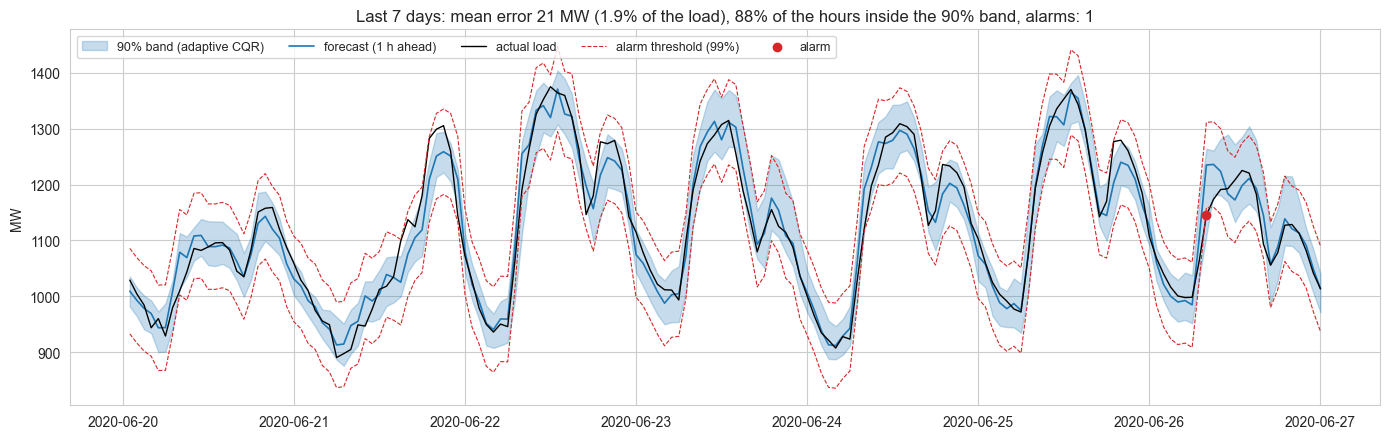

In [32]:
# Operator view: last 7 days of TEST with the 1-h-ahead forecast, the 90% adaptive band and the 99% alarms
lo_band, hi_band = intervals['Adaptive CQR (ACI, 8 weeks)']
win = y_test.index > y_test.index.max() - pd.Timedelta(days=7)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.fill_between(y_test.index[win], lo_band[win], hi_band[win], color='C0', alpha=0.25, label='90% band (adaptive CQR)')
ax.plot(y_test.index[win], yhat_test[win], color='C0', lw=1.2, label='forecast (1 h ahead)')
ax.plot(y_test.index[win], y_test[win], color='k', lw=1, label='actual load')
ax.plot(y_test.index[win], (yhat_test - q_anom)[win], color='C3', ls='--', lw=0.8, label='alarm threshold (99%)')
ax.plot(y_test.index[win], (yhat_test + q_anom)[win], color='C3', ls='--', lw=0.8)
fw = flag & win
ax.scatter(y_test.index[fw], y_test[fw], color='C3', zorder=3, label='alarm')
inside_w = ((y_test[win] >= lo_band[win]) & (y_test[win] <= hi_band[win])).mean()
ax.set_title(f'Last 7 days: mean error {mean_absolute_error(y_test[win], yhat_test[win]):.0f} MW '
             f'({100 * mean_absolute_error(y_test[win], yhat_test[win]) / y_test[win].mean():.1f}% of the load), '
             f'{inside_w:.0%} of the hours inside the 90% band, alarms: {fw.sum()}')
ax.set_ylabel('MW')
ax.legend(loc='upper left', ncol=5, fontsize=9)
plt.tight_layout()
plt.show()

**Mensajes para el equipo de operación**

- **Precisión:** la previsión de la próxima hora se equivoca de media unos **20 MW (≈ 1.7 % de la demanda)**, menos de la mitad que suponer que "la próxima hora será como la actual".
- **Qué mira el modelo:** sobre todo la demanda de la última hora y la hora del día. La demanda de hace una semana y los festivos ajustan la previsión. El tiempo meteorológico apenas cambia la previsión a una hora.
- **La banda:** contiene la demanda real **9 de cada 10 horas**. Es más ancha en las rampas de la mañana y de la tarde, y se ensancha sola cuando el sistema es más incierto (diciembre-enero, inicio de la pandemia), así que una banda ancha es en sí misma un aviso.
- **Alarmas:** un punto rojo indica que la demanda se alejó de la previsión más que en el 99 % de los casos (líneas discontinuas). Se esperan **unas 2 alarmas por semana**. Cada alarma debe revisarse con el registro de incidencias: puede ser un evento real (disparo, deslastre, fallo de medida) o un error del modelo.
- **Limitaciones y recomendaciones:**
  - El modelo **infraestima los récords de demanda** (nunca ha visto valores tan altos). Conviene reentrenarlo cada mes con los datos más recientes y, en las horas punta, planificar la reserva con el límite superior de la banda.
  - Hay que tener especial cuidado en las **rampas de las 7-9 h y de las 18-19 h**, donde se concentran los errores.
  - Ante un cambio brusco de comportamiento (como el COVID), la banda se adapta en pocos días, pero conviene revisar el modelo.
  - Para planificar el día siguiente se necesita otro modelo que use previsiones meteorológicas. Este está pensado para la operación en tiempo real.